# 딥러닝의 이해 과제3
## 202110942 정주연

## 부산 도시철도 월별 승객 수의 딥러닝 기반 시계열 예측

## 1. Data Preparation

### 1.1 Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 시각화 기본 설정
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11

# 데이터 출력 형식 설정
pd.options.display.float_format = '{:,.2f}'.format

### 1.2 Data Loading and Inspection

In [2]:
# 데이터 불러오기
df = pd.read_csv(r"C:\Users\wndus\Downloads\all_monthly.csv")

# 데이터 크기 확인
print('Data shape:', df.shape)

# 처음 5개 관측치
display(df.head())

# 마지막 5개 관측치
display(df.tail())

# 변수 및 자료형 확인
df.info()

Data shape: (130, 2)


,Time,Total
0,2015-01,26761286
1,2015-02,23561132
2,2015-03,28813892
3,2015-04,27932022
4,2015-05,28928232


,Time,Total
125,2025-06,25866571
126,2025-07,27078366
127,2025-08,26113880
128,2025-09,27240678
129,2025-10,26435897


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 130 entries, 0 to 129
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Time    130 non-null    object
 1   Total   130 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 2.2+ KB


### 1.3 Time Series Formatting

In [3]:
# 날짜 형식 변환
df['Time'] = pd.to_datetime(df['Time'], format='%Y-%m')

# 시간 순서에 따른 정렬
df = df.sort_values('Time')

# 날짜 변수를 인덱스로 설정
df = df.set_index('Time')

# 변환 결과 확인
display(df.head())

print('Index type:', df.index.dtype)
print('Start date:', df.index.min())
print('End date:', df.index.max())

,Total
Time,
2015-01-01,26761286
2015-02-01,23561132
2015-03-01,28813892
2015-04-01,27932022
2015-05-01,28928232


Index type: datetime64[ns]
Start date: 2015-01-01 00:00:00
End date: 2025-10-01 00:00:00


### 1.4 Data Quality Assessment

In [4]:
# 전체 분석 기간에 해당하는 월별 날짜 생성
expected_dates = pd.date_range(
    start='2015-01-01',
    end='2025-10-01',
    freq='MS'
)

# 누락된 관측 월 확인
missing_dates = expected_dates.difference(df.index)

# 분석 기간을 벗어난 관측 월 확인
unexpected_dates = df.index.difference(expected_dates)

# 데이터 품질 검증 결과
quality_check = pd.DataFrame({
    'Check': [
        'Total observations',
        'Missing values',
        'Duplicate timestamps',
        'Missing months',
        'Unexpected months',
        'Zero values',
        'Negative values'
    ],
    'Result': [
        len(df),
        df['Total'].isnull().sum(),
        df.index.duplicated().sum(),
        len(missing_dates),
        len(unexpected_dates),
        (df['Total'] == 0).sum(),
        (df['Total'] < 0).sum()
    ]
})

display(quality_check)

# 시간 순서 확인
print('Chronological order:', df.index.is_monotonic_increasing)

# 누락된 관측 월 확인
print('Missing dates:', missing_dates.tolist())

,Check,Result
0,Total observations,130
1,Missing values,0
2,Duplicate timestamps,0
3,Missing months,0
4,Unexpected months,0
5,Zero values,0
6,Negative values,0


Chronological order: True
Missing dates: []


### 1.5 Time Series Construction

In [5]:
# 월별 시계열 빈도 설정
df = df.asfreq('MS')

# 단변량 시계열 생성
ts = df['Total'].astype(float)

# 시계열 정보 확인
print('Frequency:', ts.index.freqstr)
print('Data type:', ts.dtype)

Frequency: MS
Data type: float64


전체 130개의 월별 관측치에서 결측치, 중복 및 누락된
관측 월이 발견되지 않았다. 모든 관측값이 양수이므로
별도의 데이터 정제 없이 시계열 분석과 제곱근 및 로그
변환을 수행할 수 있다.

## 2. Exploratory Data Analysis (EDA)

### 2.1 Descriptive Statistics

In [6]:
# 기초통계량 산출
summary = ts.describe().to_frame(name='Total')

# 추가적인 기초통계량
summary.loc['variance'] = ts.var()
summary.loc['CV (%)'] = (ts.std() / ts.mean()) * 100
summary.loc['skewness'] = ts.skew()
summary.loc['kurtosis'] = ts.kurt()

display(summary)

,Total
count,130.00
mean,"25,691,947.21"
std,"3,226,287.06"
min,"14,979,139.00"
25%,"23,769,563.50"
50%,"26,459,560.00"
75%,"27,909,329.00"
max,"30,453,129.00"
variance,"10,408,928,214,855.16"
CV (%),12.56


### 2.2 Time Series Visualization

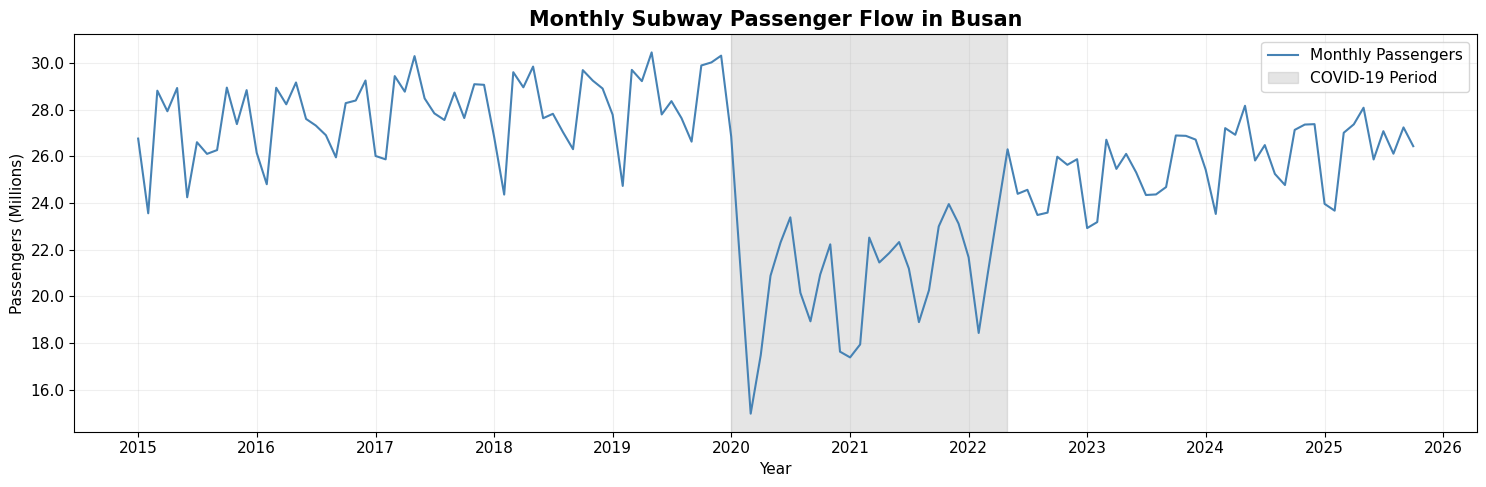

In [7]:
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

# 코로나19 기간
covid_start = pd.Timestamp('2020-01-01')
covid_end = pd.Timestamp('2022-04-30')

fig, ax = plt.subplots(figsize=(15, 5))

# 월별 승객 수
ax.plot(
    ts.index, ts,
    color='steelblue',
    linewidth=1.5,
    label='Monthly Passengers'
)

# 코로나19 기간 음영 표시
ax.axvspan(
    covid_start, covid_end,
    color='gray',
    alpha=0.2,
    label='COVID-19 Period'
)

# 그래프 설정
ax.set_title('Monthly Subway Passenger Flow in Busan',
             fontsize=15, fontweight='bold')

ax.set_xlabel('Year')
ax.set_ylabel('Passengers (Millions)')

# 승객 수를 백만 명 단위로 표시
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f'{x / 1e6:.1f}')
)

# 연도별 눈금 설정
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### 2.3 Monthly Seasonal Patterns

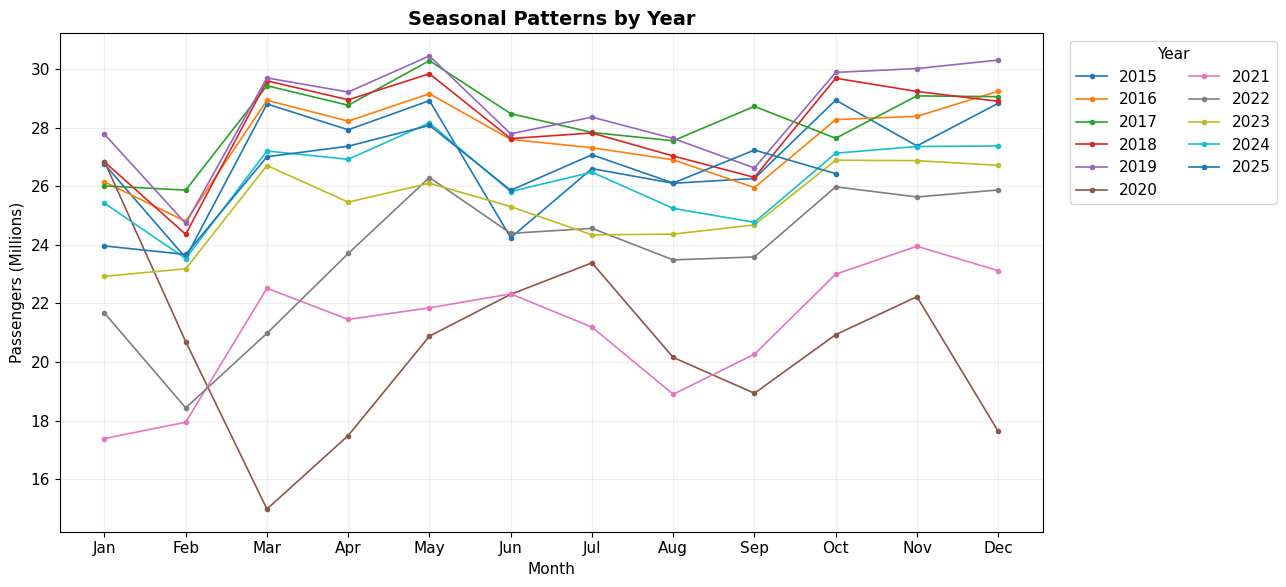

In [8]:
# 계절성 분석용 데이터 생성
seasonal_df = ts.to_frame(name='Passengers')
seasonal_df['Year'] = seasonal_df.index.year
seasonal_df['Month'] = seasonal_df.index.month

# 연도별·월별 데이터 구성
seasonal_pivot = seasonal_df.pivot(
    index='Month',
    columns='Year',
    values='Passengers'
)

month_labels = [
    'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'
]

# Seasonal Plot
fig, ax = plt.subplots(figsize=(13, 6))

for year in seasonal_pivot.columns:

    ax.plot(
        seasonal_pivot.index,
        seasonal_pivot[year] / 1e6,
        marker='o',
        markersize=3,
        linewidth=1.2,
        label=str(year)
    )

ax.set_title('Seasonal Patterns by Year',
             fontsize=14, fontweight='bold')

ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_labels)

ax.set_xlabel('Month')
ax.set_ylabel('Passengers (Millions)')

ax.legend(title='Year', ncol=2, bbox_to_anchor=(1.02, 1))
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### 2.4 STL Decomposition

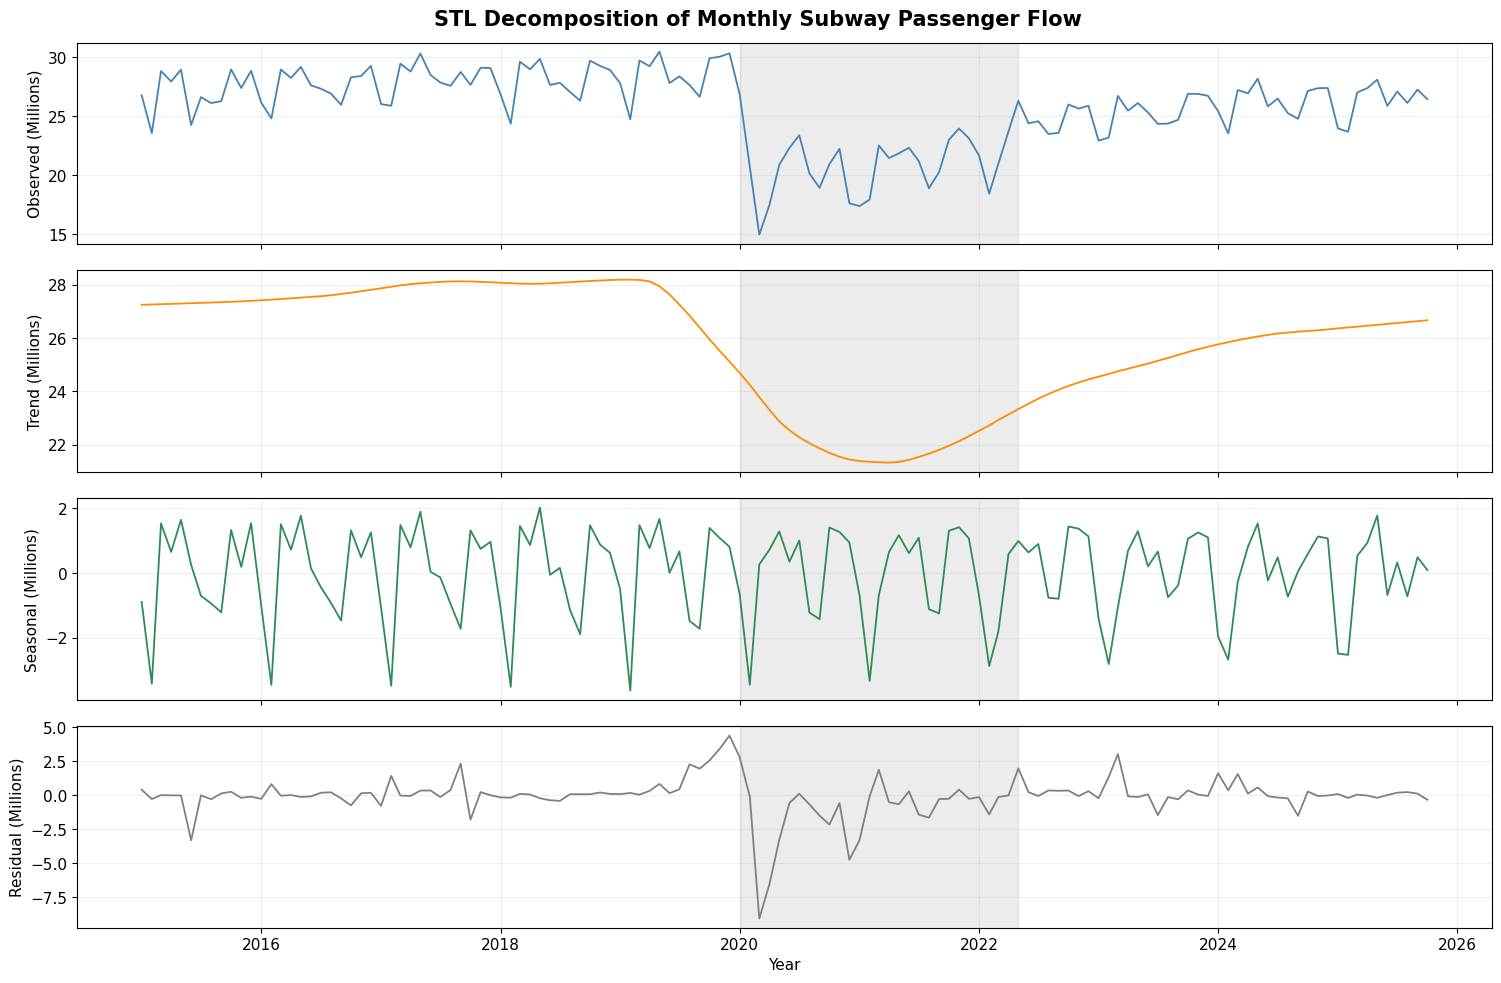

In [9]:
from statsmodels.tsa.seasonal import STL

# STL 분해
stl = STL(
    ts,
    period=12,
    robust=True
)

stl_result = stl.fit()

# 분해 결과 시각화
fig, axes = plt.subplots(
    4, 1,
    figsize=(15, 10),
    sharex=True
)

components = [
    ts,
    stl_result.trend,
    stl_result.seasonal,
    stl_result.resid
]

titles = [
    'Observed (Millions)',
    'Trend (Millions)',
    'Seasonal (Millions)',
    'Residual (Millions)'
]

colors = [
    'steelblue',
    'darkorange',
    'seagreen',
    'gray'
]

for ax, component, title, color in zip(
    axes, components, titles, colors
):

    ax.plot(
        component.index,
        component / 1e6,
        color=color,
        linewidth=1.3
    )

    ax.axvspan(
        covid_start, covid_end,
        color='gray',
        alpha=0.15
    )

    ax.set_ylabel(title)
    ax.grid(alpha=0.2)

axes[-1].set_xlabel('Year')

fig.suptitle(
    'STL Decomposition of Monthly Subway Passenger Flow',
    fontsize=15,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

### 2.5 Interpretation

- **추세(Trend)**

  코로나19 이전에는 완만한 증가 추세가 나타났으나
  코로나19 발생 이후 승객 수가 급격하게 감소하였다.
  이후 점진적인 회복 추세가 관찰되지만 분석 기간 말까지
  코로나19 이전의 추세 수준을 완전히 회복하지는 못하였다.

- **계절성(Seasonality)**

  연도별 Seasonal Plot과 STL 분해 결과에서 12개월 단위의
  반복적인 계절 패턴이 관찰되었다.
  다만 월별 일수 차이가 전체 승객 수에 영향을 미칠 수 있으므로
  이를 고려하여 해석할 필요가 있다.

- **변동성 및 구조적 변화(Variability and Structural Change)**

  코로나19 발생 초기에는 큰 음의 잔차가 관찰되었으며,
  이는 해당 시기의 급격한 승객 수 감소가 일반적인 추세와
  계절성만으로 충분히 설명되기 어려움을 나타낸다.

- **향후 분석 방향**

  이러한 탐색적 분석 결과를 바탕으로 추세, 계절성 및
  시간적 의존성을 고려한 시계열 예측 모형을 구축하고자 한다.
  구체적인 전처리 방법과 하이퍼파라미터는 시계열 교차검증의
  학습 데이터를 기반으로 결정한다.

## 3. Time-Series Cross-Validation

### 3.1 Time-Series CV Design

시계열의 시간적 순서를 유지하기 위해 Expanding Window 방식의
5-Fold Time-Series Cross-Validation을 적용하였다.
연간 계절 주기를 고려하여 각 테스트 구간을 12개월로 설정하였으며,
모든 모델에 동일한 데이터 분할을 적용한다.

In [10]:
from sklearn.model_selection import TimeSeriesSplit

# 교차검증 설정
n_splits = 5
test_size = 12

tscv = TimeSeriesSplit(
    n_splits=n_splits,
    test_size=test_size,
    gap=0
)

# 교차검증 인덱스 저장
cv_splits = list(tscv.split(ts))

print('Total observations:', len(ts))
print('Number of folds:', n_splits)
print('Test size:', test_size)
print('Initial training size:', len(cv_splits[0][0]))

Total observations: 130
Number of folds: 5
Test size: 12
Initial training size: 70


### 3.2 Training and Test Sets

In [11]:
cv_results = []

for fold, (train_idx, test_idx) in enumerate(
    cv_splits, start=1
):

    train = ts.iloc[train_idx]
    test = ts.iloc[test_idx]

    cv_results.append({
        'Fold': fold,
        'Train Start': train.index[0].strftime('%Y-%m'),
        'Train End': train.index[-1].strftime('%Y-%m'),
        'Train Size': len(train),
        'Test Start': test.index[0].strftime('%Y-%m'),
        'Test End': test.index[-1].strftime('%Y-%m'),
        'Test Size': len(test)
    })

# 교차검증 분할 결과
cv_summary = pd.DataFrame(cv_results)

display(cv_summary)

,Fold,Train Start,Train End,Train Size,Test Start,Test End,Test Size
0,1,2015-01,2020-10,70,2020-11,2021-10,12
1,2,2015-01,2021-10,82,2021-11,2022-10,12
2,3,2015-01,2022-10,94,2022-11,2023-10,12
3,4,2015-01,2023-10,106,2023-11,2024-10,12
4,5,2015-01,2024-10,118,2024-11,2025-10,12


### 3.3 Visualization of Time-Series CV

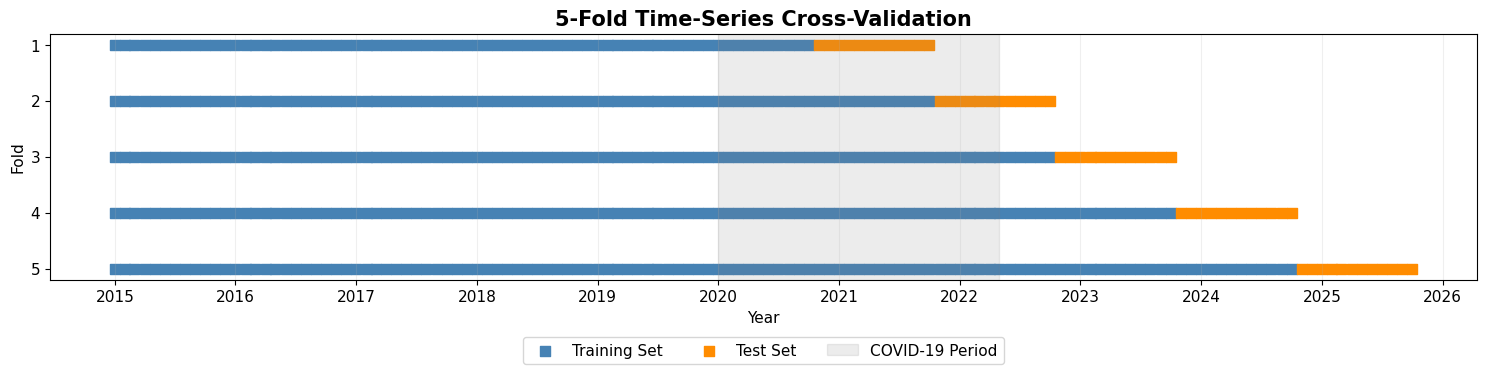

In [12]:
fig, ax = plt.subplots(figsize=(15, 4))

for fold, (train_idx, test_idx) in enumerate(
    cv_splits, start=1
):

    # Training 구간
    ax.scatter(
        ts.index[train_idx],
        np.full(len(train_idx), fold),
        marker='s',
        s=45,
        color='steelblue',
        label='Training Set' if fold == 1 else None
    )

    # Test 구간
    ax.scatter(
        ts.index[test_idx],
        np.full(len(test_idx), fold),
        marker='s',
        s=45,
        color='darkorange',
        label='Test Set' if fold == 1 else None
    )

# 코로나19 기간 표시
ax.axvspan(
    covid_start,
    covid_end,
    color='gray',
    alpha=0.15,
    label='COVID-19 Period'
)

# 그래프 설정
ax.set_title(
    '5-Fold Time-Series Cross-Validation',
    fontsize=15,
    fontweight='bold'
)

ax.set_xlabel('Year')
ax.set_ylabel('Fold')

ax.set_yticks(range(1, n_splits + 1))
ax.invert_yaxis()

ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

ax.legend(loc='upper center',
          bbox_to_anchor=(0.5, -0.2),
          ncol=3)

ax.grid(axis='x', alpha=0.2)

plt.tight_layout()
plt.show()

## 4. Data Preprocessing

### 4.1 Preprocessing Methods

시계열 자료의 추세 및 변동 특성을 고려하여 다음 세 가지
전처리 방법을 적용하고 원자료와 비교한다.

#### (1) First-order Differencing

$$
z_t = y_t-y_{t-1}
$$

인접한 시점의 관측값 간 차이를 계산하여 추세를 완화하고
시계열의 정상성을 개선한다.

#### (2) Square-root Transformation

$$
z_t = \sqrt{y_t}
$$

큰 관측값의 변동 폭을 상대적으로 축소하여 분산 안정화를 유도한다.

#### (3) Log Transformation

$$
z_t = \log(y_t)
$$

관측값의 규모에 따른 변동 폭을 완화하고 분산 안정화를 유도한다.

모든 전처리 효과는 각 Fold의 학습 데이터를 기준으로 비교한다.

In [13]:
# 전처리 함수 정의
def transform_series(series):

    transformed = {
        'Original': series.copy(),
        'Differencing': series.diff().dropna(),
        'Square Root': np.sqrt(series),
        'Log': np.log(series)
    }

    return transformed


# Fold별 학습 데이터 전처리
transformed_data = {}

for fold, (train_idx, test_idx) in enumerate(
    cv_splits, start=1
):

    train = ts.iloc[train_idx]

    transformed_data[fold] = transform_series(train)


# Fold별 전처리 이후 관측치 수 확인
transform_summary = pd.DataFrame({
    fold: {
        method: len(series)
        for method, series in data.items()
    }
    for fold, data in transformed_data.items()
}).T

transform_summary.index.name = 'Fold'

display(transform_summary)

,Original,Differencing,Square Root,Log
Fold,,,,
1,70,69,70,70
2,82,81,82,82
3,94,93,94,94
4,106,105,106,106
5,118,117,118,118


### 4.2 Visualization of Transformed Data

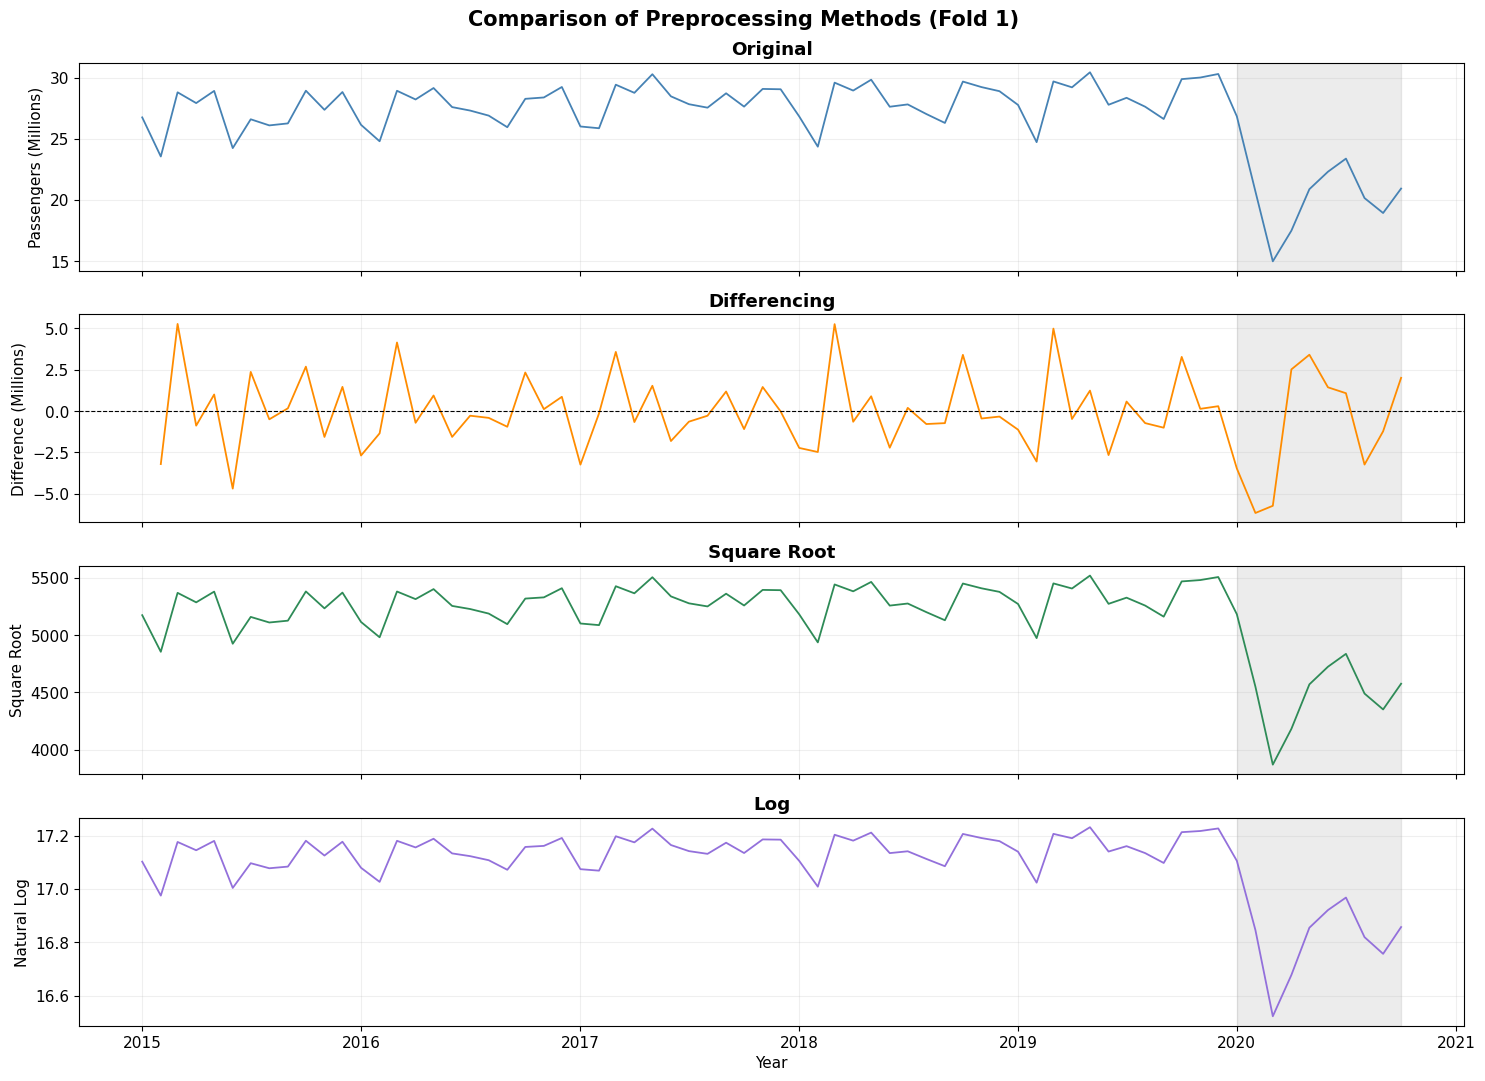

In [14]:
# 시각화에 사용할 대표 Fold
selected_fold = 1

data = transformed_data[selected_fold]

fig, axes = plt.subplots(
    4, 1,
    figsize=(15, 11),
    sharex=True
)

colors = [
    'steelblue',
    'darkorange',
    'seagreen',
    'mediumpurple'
]

ylabels = [
    'Passengers (Millions)',
    'Difference (Millions)',
    'Square Root',
    'Natural Log'
]

for ax, (method, series), color, ylabel in zip(
    axes, data.items(), colors, ylabels
):

    # 원자료 및 차분은 백만 명 단위로 표시
    if method in ['Original', 'Differencing']:
        values = series / 1e6
    else:
        values = series

    ax.plot(
        series.index,
        values,
        color=color,
        linewidth=1.3
    )

    # 코로나19 기간 표시
    ax.axvspan(
        covid_start,
        min(covid_end, series.index[-1]),
        color='gray',
        alpha=0.15
    )

    # 차분 결과의 기준선
    if method == 'Differencing':
        ax.axhline(
            0,
            color='black',
            linestyle='--',
            linewidth=0.8
        )

    ax.set_title(method, fontweight='bold')
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.2)

axes[-1].set_xlabel('Year')

axes[-1].xaxis.set_major_locator(mdates.YearLocator())
axes[-1].xaxis.set_major_formatter(
    mdates.DateFormatter('%Y')
)

fig.suptitle(
    f'Comparison of Preprocessing Methods (Fold {selected_fold})',
    fontsize=15,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

### 4.3 Stationarity Test

각 전처리 방법의 정상성 개선 효과를 비교하기 위해
Augmented Dickey-Fuller(ADF) 검정과
Kwiatkowski-Phillips-Schmidt-Shin(KPSS) 검정을 실시한다.

두 검정의 유의수준은 0.05로 설정한다.

ADF 검정의 귀무가설은 단위근이 존재한다는 것이며,
KPSS 검정의 귀무가설은 수준 정상성을 만족한다는 것이다.

두 검정의 결과는 정상성에 대한 통계적 근거로 활용하며,
정상성의 성립 여부를 확정하는 것으로 해석하지 않는다.

KPSS 검정의 p-value는 제공되는 임계값의 범위에 따라
경곗값으로 표시될 수 있다.

In [15]:
import warnings
from statsmodels.tools.sm_exceptions import InterpolationWarning
from statsmodels.tsa.stattools import adfuller, kpss

# 정상성 검정 함수
def stationarity_test(series):

    # ADF Test
    adf_result = adfuller(
        series,
        regression='c',
        autolag='AIC'
    )

    # KPSS Test
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', InterpolationWarning)

        kpss_result = kpss(
            series,
            regression='c',
            nlags='auto'
        )
    
    return {
        'ADF Statistic': adf_result[0],
        'ADF p-value': adf_result[1],
        'KPSS Statistic': kpss_result[0],
        'KPSS p-value': kpss_result[1]
    }


# Fold별·전처리 방법별 정상성 검정
stationarity_results = []

for fold, data in transformed_data.items():

    for method, series in data.items():

        result = stationarity_test(series)

        stationarity_results.append({
            'Fold': fold,
            'Method': method,
            **result
        })


stationarity_df = pd.DataFrame(stationarity_results)

# 검정 결과 출력
display(
    stationarity_df.style.format({
        'ADF Statistic': '{:.4f}',
        'ADF p-value': '{:.4e}',
        'KPSS Statistic': '{:.4f}',
        'KPSS p-value': '{:.4f}'
    })
)

,Fold,Method,ADF Statistic,ADF p-value,KPSS Statistic,KPSS p-value
0,1,Original,-0.7652,8.2914e-01,0.4233,0.0671
1,1,Differencing,-2.2772,1.7943e-01,0.0810,0.1000
2,1,Square Root,-0.8417,8.0658e-01,0.4366,0.0614
3,1,Log,-0.9320,7.7726e-01,0.4490,0.0561
4,2,Original,-1.0716,7.2625e-01,0.7841,0.0100
5,2,Differencing,-7.4573,5.4690e-11,0.0652,0.1000
6,2,Square Root,-1.1463,6.9628e-01,0.7923,0.0100
7,2,Log,-1.5501,5.0859e-01,0.7992,0.0100
8,3,Original,-1.4167,5.7426e-01,0.9182,0.0100
9,3,Differencing,-8.2956,4.1475e-13,0.0682,0.1000


In [16]:
# ADF 및 KPSS 검정 결과 종합
def evaluate_stationarity(row):

    adf_reject = row['ADF p-value'] < 0.05
    kpss_reject = row['KPSS p-value'] < 0.05

    if adf_reject and not kpss_reject:
        return 'Stationary'

    elif not adf_reject and kpss_reject:
        return 'Non-stationary'

    else:
        return 'Inconclusive'


stationarity_df['Conclusion'] = (
    stationarity_df.apply(
        evaluate_stationarity,
        axis=1
    )
)

# 전처리 방법별 정상성 판단 결과
stationarity_summary = stationarity_df.pivot(
    index='Fold',
    columns='Method',
    values='Conclusion'
)

stationarity_summary = stationarity_summary[
    ['Original', 'Differencing', 'Square Root', 'Log']
]

display(stationarity_summary)

Method,Original,Differencing,Square Root,Log
Fold,,,,
1,Inconclusive,Inconclusive,Inconclusive,Inconclusive
2,Non-stationary,Stationary,Non-stationary,Non-stationary
3,Non-stationary,Stationary,Non-stationary,Non-stationary
4,Non-stationary,Stationary,Non-stationary,Non-stationary
5,Non-stationary,Stationary,Non-stationary,Non-stationary


### 4.4 Autocorrelation Analysis

자기상관함수(ACF)를 이용하여 원자료와 전처리된 시계열의
시차별 자기상관 구조를 비교한다.

특히 연간 계절 주기에 해당하는 Lag 12 및 Lag 24의
자기상관 특성을 확인한다.

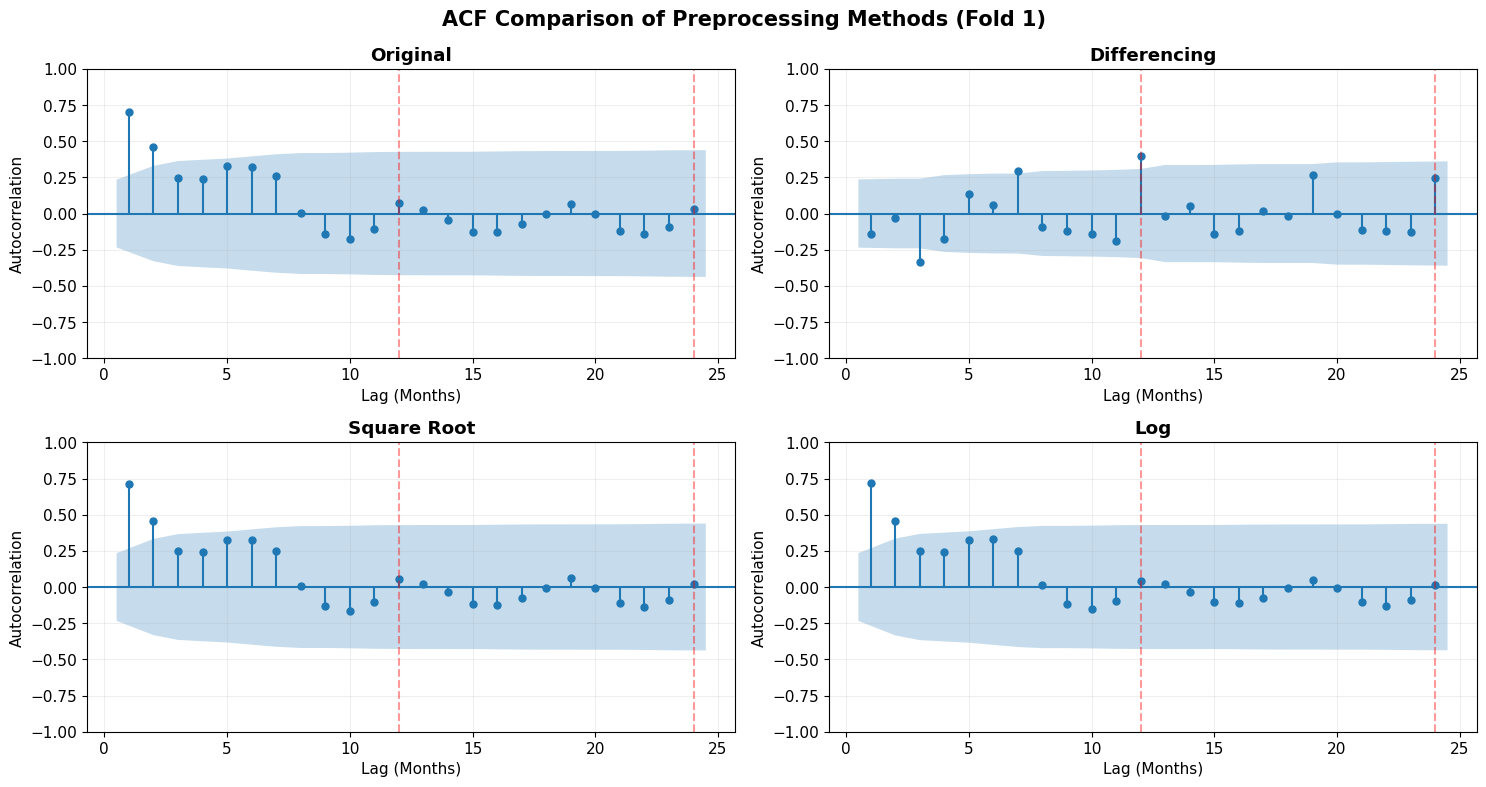

In [17]:
from statsmodels.graphics.tsaplots import plot_acf

data = transformed_data[selected_fold]

fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 8)
)

for ax, (method, series) in zip(
    axes.flatten(), data.items()
):

    plot_acf(
        series,
        lags=24,
        zero=False,
        alpha=0.05,
        ax=ax
    )

    # 계절 주기에 해당하는 시차 표시
    for lag in [12, 24]:

        ax.axvline(
            lag,
            color='red',
            linestyle='--',
            alpha=0.4
        )

    ax.set_title(method, fontweight='bold')
    ax.set_xlabel('Lag (Months)')
    ax.set_ylabel('Autocorrelation')
    ax.grid(alpha=0.2)

fig.suptitle(
    f'ACF Comparison of Preprocessing Methods (Fold {selected_fold})',
    fontsize=15,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

### 4.5 Preprocessing Selection

- **전처리 결과 비교**

  제곱근 변환과 로그 변환은 관측값의 규모를 압축하였으나
  원자료의 추세 및 수준 변화가 여전히 유지되었다.
  반면 1차 차분에서는 관측값이 대체로 0을 중심으로
  변동하는 양상이 나타났다.

- **정상성 검정**

  ADF 및 KPSS 검정 결과, 1차 차분은 Fold 2~5에서
  정상성을 지지하는 결과를 나타냈다.
  Fold 1에서는 정상성 여부에 대한 판단이 유보되었다.

- **자기상관 분석**

  제곱근 및 로그 변환 이후에는 원자료와 유사한
  자기상관 구조가 유지되었다.

  1차 차분 이후에는 단기 자기상관이 감소하였으며,
  Lag 12에서 양의 자기상관이 관찰되었다.
  이는 차분 이후에도 연간 계절적 의존성이
  남아 있을 가능성을 보여준다.

- **최종 전처리 방법 선정**

  시계열 그래프, 정상성 검정 및 자기상관 분석 결과를
  종합적으로 고려하여 1차 차분을 공통 전처리 방법으로
  선정하였다.

  다만 정상성 개선이 딥러닝 모델의 예측 성능 향상을
  반드시 보장하는 것은 아니며, 본 연구에서는 동일한
  전처리 조건에서 모델별 예측 성능을 비교하고자 한다.


각 Fold의 학습 데이터에서 전처리 특성을 평가하였으나,
모든 Fold의 결과를 종합하여 공통 전처리 방법을 선정하였다.

따라서 전처리 방법의 선정 과정까지 완전히 독립적인
교차검증으로 구성된 것은 아니라는 한계가 존재한다.

### 4.6 Data Scaling

딥러닝 모델 학습의 수치적 안정성을 확보하기 위해
1차 차분된 시계열에 Standardization을 적용한다.

$$
z_t = \frac{\Delta y_t-\mu_{train}}{\sigma_{train}}
$$

데이터 누출을 방지하기 위해 각 Fold의 학습 데이터에서
평균과 표준편차를 추정한다.

테스트 구간은 실제 관측값을 입력하지 않고 재귀적으로
예측하며, 예측된 표준화 차분값은 학습 데이터에서
추정한 변환 기준을 이용하여 역변환한다.

In [18]:
from sklearn.preprocessing import StandardScaler

# 선정된 전처리 방법
selected_method = 'Differencing'

# Fold별 전처리 및 스케일링 결과 저장
scaled_data = {}
scalers = {}

for fold in range(1, n_splits + 1):

    # Fold별 차분된 학습 데이터
    train_diff = transformed_data[fold][selected_method]

    # 스케일러 생성
    scaler = StandardScaler()

    # 학습 데이터 기준 스케일링
    train_scaled = scaler.fit_transform(
        train_diff.to_numpy().reshape(-1, 1)
    )

    # 결과 저장
    scaled_data[fold] = train_scaled
    scalers[fold] = scaler

In [19]:
scaling_results = []

for fold, values in scaled_data.items():

    scaling_results.append({
        'Fold': fold,
        'Observations': len(values),
        'Mean': np.mean(values),
        'Std': np.std(values),
        'Min': np.min(values),
        'Max': np.max(values)
    })

scaling_summary = pd.DataFrame(scaling_results)

display(scaling_summary.round(4))

,Fold,Observations,Mean,Std,Min,Max
0,1,69,-0.00,1.00,-2.57,2.26
1,2,81,0.00,1.00,-2.60,2.26
2,3,93,-0.00,1.00,-2.67,2.29
3,4,105,-0.00,1.00,-2.76,2.36
4,5,117,-0.00,1.00,-2.83,2.41


## 5. Deep Learning Model Construction

### 5.1 Experimental Setup

In [20]:
import tensorflow as tf
tf.get_logger().setLevel('ERROR')

from tensorflow import keras
from tensorflow.keras import layers

# 난수 시드 설정
SEED = 42

keras.utils.set_random_seed(SEED)

# 결정론적 연산 설정
tf.config.experimental.enable_op_determinism()

# 실험 환경 확인
print('TensorFlow version:', tf.__version__)
print('NumPy version:', np.__version__)
print('Pandas version:', pd.__version__)
print('Random seed:', SEED)

TensorFlow version: 2.21.0
NumPy version: 2.3.5
Pandas version: 2.3.3
Random seed: 42


### 5.2 Input Sequence Construction

월별 시계열의 연간 계절적 의존성과 제한적인 관측치 수를
고려하여 Lookback window를 12개월로 설정한다.

과거 12개월의 표준화된 차분값을 입력으로 사용하고
다음 시점의 표준화된 차분값을 예측 대상으로 설정한다.

$$
\mathbf{X}_t=(z_{t-12},z_{t-11},\ldots,z_{t-1})
$$

$$
Y_t=z_t
$$

모든 딥러닝 모델에 동일한 입력 시퀀스를 적용하여
일관된 조건에서 예측 성능을 비교한다.

In [21]:
# 입력 시퀀스 길이
LOOKBACK = 12

# 입력 및 출력 시퀀스 생성 함수
def create_sequences(data, lookback):

    data = np.asarray(data, dtype=np.float32).reshape(-1, 1)

    X, y = [], []

    for i in range(len(data) - lookback):

        X.append(data[i:i + lookback])
        y.append(data[i + lookback, 0])

    return np.array(X), np.array(y)


# Fold별 학습 시퀀스 생성
sequence_data = {}

for fold, values in scaled_data.items():

    X_train, y_train = create_sequences(
        values,
        LOOKBACK
    )

    sequence_data[fold] = {
        'X_train': X_train,
        'y_train': y_train
    }

In [22]:
# Fold별 입력 및 출력 데이터 구조 확인
sequence_summary = pd.DataFrame([
    {
        'Fold': fold,
        'Samples': len(data['X_train']),
        'X_train shape': data['X_train'].shape,
        'y_train shape': data['y_train'].shape
    }
    for fold, data in sequence_data.items()
])

display(sequence_summary)

,Fold,Samples,X_train shape,y_train shape
0,1,57,"(57, 12, 1)","(57,)"
1,2,69,"(69, 12, 1)","(69,)"
2,3,81,"(81, 12, 1)","(81,)"
3,4,93,"(93, 12, 1)","(93,)"
4,5,105,"(105, 12, 1)","(105,)"


### 5.3 Forecasting Strategy

테스트 구간 및 미래 예측에는 Recursive Forecasting을 적용한다.

초기 예측에는 학습 데이터의 마지막 12개 관측값을 사용하고
이후에는 이전 시점의 예측값을 입력 시퀀스에 추가하여
다음 시점의 값을 순차적으로 예측한다.

예측된 표준화 차분값은 표준화의 역변환과 차분의 역변환을
거쳐 원래 승객 수 단위로 복원한다.

#### 5.3.1 Recursive Forecasting

In [23]:
# 재귀적 다단계 예측 함수
def recursive_forecast(model, initial_sequence, steps):

    sequence = np.asarray(
        initial_sequence, dtype=np.float32
    ).reshape(1, -1, 1)

    predictions = []

    for _ in range(steps):

        # 다음 시점 예측
        prediction = float(
            model(sequence, training=False).numpy().item()
        )

        predictions.append(prediction)

        # 가장 오래된 값 제거 및 새로운 예측값 추가
        sequence = np.concatenate(
            [
                sequence[:, 1:, :],
                np.array([[[prediction]]], dtype=np.float32)
            ],
            axis=1
        )

    return np.array(predictions)

#### 5.3.2 Inverse Transformation

예측 결과를 원래 승객 수 단위로 복원하기 위해
Standardization의 역변환을 수행한 후, 학습 데이터의
마지막 실제 관측값을 기준으로 예측 차분값을 누적한다.

$$
\widehat{\Delta y}_t
=\hat{z}_t\sigma_{train}+\mu_{train}
$$

$$
\hat{y}_{T+h}
=y_T+\sum_{i=1}^{h}\widehat{\Delta y}_{T+i}
$$

In [24]:
# 표준화 및 차분 역변환 함수
def inverse_forecast(predictions, scaler, last_actual):

    # 표준화 역변환
    predicted_diff = scaler.inverse_transform(
        np.asarray(predictions).reshape(-1, 1)
    ).flatten()

    # 차분 역변환
    predicted_values = last_actual + np.cumsum(predicted_diff)

    return predicted_values

#### 5.3.3 Evaluation Metrics

모델별 예측 성능은 Root Mean Squared Error(RMSE)와
Mean Absolute Error(MAE)를 이용하여 평가한다.

모든 평가 지표는 역변환 이후 원래 승객 수 단위에서 산출한다.

$$
RMSE=\sqrt{\frac{1}{n}\sum_{t=1}^{n}(y_t-\hat{y}_t)^2}
$$

$$
MAE=\frac{1}{n}\sum_{t=1}^{n}|y_t-\hat{y}_t|
$$

In [25]:
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error

# 예측 성능 평가 함수
def evaluate_predictions(actual, predicted):

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    mae = mean_absolute_error(actual, predicted)

    return rmse, mae

### 5.4 Training Configuration

#### 5.4.1 Hyperparameter Settings

In [26]:
# 공통 학습 하이퍼파라미터
LEARNING_RATE = 0.001
MAX_EPOCHS = 200
BATCH_SIZE = 8
VALIDATION_SIZE = 12
PATIENCE = 20

In [27]:
# 공통 하이퍼파라미터 확인
training_config = pd.DataFrame({
    'Hyperparameter': [
        'Lookback window',
        'Optimizer',
        'Learning rate',
        'Loss function',
        'Maximum epochs',
        'Batch size',
        'Validation size',
        'Early stopping patience',
        'Shuffle',
        'Random seed'
    ],
    'Value': [
        LOOKBACK,
        'Adam',
        f'{LEARNING_RATE:.4f}',
        'MSE',
        MAX_EPOCHS,
        BATCH_SIZE,
        VALIDATION_SIZE,
        PATIENCE,
        False,
        SEED
    ]
})

display(training_config)

,Hyperparameter,Value
0,Lookback window,12
1,Optimizer,Adam
2,Learning rate,0.0010
3,Loss function,MSE
4,Maximum epochs,200
5,Batch size,8
6,Validation size,12
7,Early stopping patience,20
8,Shuffle,False
9,Random seed,42


#### Rationale for Hyperparameter Settings

12개월의 입력 시퀀스는 월별 자료의 연간 계절 주기와
제한적인 학습 표본 수를 고려하여 설정하였다.

Adam과 학습률 0.001은 일반적인 신경망 학습 설정을
참고하였으며, 연속형 표준화 차분값을 예측하기 위해
MSE를 손실함수로 사용하였다.

Batch size를 8로 설정하여 제한적인 학습 표본에서도
여러 차례의 가중치 갱신이 이루어지도록 하였다.

최대 학습 횟수는 200으로 제한하고 검증 손실이
20 Epoch 동안 개선되지 않을 경우 학습을 중단하도록
설정하였다.

모델별 비교 조건을 통일하고 실험의 재현성을 높이기 위해
동일한 난수 시드와 학습 설정을 적용하였다.

이러한 설정은 자료의 특성과 모델 복잡도를 고려한
실험적 설계이며, 별도의 초모수 최적화를 통해
도출된 최적값은 아니다.

#### 5.4.2 Internal Validation

In [28]:
# 내부 검증 데이터 생성 함수
def prepare_validation_data(train_series):

    # 학습 데이터 내부 분할
    inner_train = train_series.iloc[:-VALIDATION_SIZE]

    # 1차 차분
    inner_diff = inner_train.diff().dropna()

    # 내부 학습 데이터 기준 스케일링
    inner_scaler = StandardScaler()

    inner_scaled = inner_scaler.fit_transform(
        inner_diff.to_numpy().reshape(-1, 1)
    )

    # 전체 학습 구간의 차분 및 변환
    full_diff = train_series.diff().dropna()

    full_scaled = inner_scaler.transform(
        full_diff.to_numpy().reshape(-1, 1)
    )

    # 내부 학습 시퀀스
    X_inner, y_inner = create_sequences(
        inner_scaled, LOOKBACK
    )

    # 전체 시퀀스에서 검증 시퀀스 추출
    X_full, y_full = create_sequences(
        full_scaled, LOOKBACK
    )

    X_val = X_full[-VALIDATION_SIZE:]
    y_val = y_full[-VALIDATION_SIZE:]

    return X_inner, y_inner, X_val, y_val

In [29]:
# Fold별 내부 검증 데이터 구성
validation_data = {}

for fold, (train_idx, test_idx) in enumerate(
    cv_splits, start=1
):

    train = ts.iloc[train_idx]

    X_inner, y_inner, X_val, y_val = (
        prepare_validation_data(train)
    )

    validation_data[fold] = {
        'X_inner': X_inner,
        'y_inner': y_inner,
        'X_val': X_val,
        'y_val': y_val
    }


# 내부 검증 데이터 구조 확인
validation_summary = pd.DataFrame([
    {
        'Fold': fold,
        'Training Samples': len(data['X_inner']),
        'Validation Samples': len(data['X_val']),
        'X_inner shape': data['X_inner'].shape,
        'X_val shape': data['X_val'].shape
    }
    for fold, data in validation_data.items()
])

display(validation_summary)

,Fold,Training Samples,Validation Samples,X_inner shape,X_val shape
0,1,45,12,"(45, 12, 1)","(12, 12, 1)"
1,2,57,12,"(57, 12, 1)","(12, 12, 1)"
2,3,69,12,"(69, 12, 1)","(12, 12, 1)"
3,4,81,12,"(81, 12, 1)","(12, 12, 1)"
4,5,93,12,"(93, 12, 1)","(12, 12, 1)"


#### 5.4.3 Early Stopping

In [30]:
# Early Stopping 생성 함수
def create_early_stopping():

    return keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=PATIENCE,
        mode='min',
        restore_best_weights=True
    )

#### 5.4.4 Common Training and Evaluation

In [31]:
# 공통 모델 학습 및 평가 함수
def train_and_evaluate(build_model, model_name):

    results = []
    predictions = {}
    histories = {}

    for fold, (train_idx, test_idx) in enumerate(
        cv_splits, start=1
    ):

        # ---------------------------------
        # 1. 데이터 준비
        # ---------------------------------
        train = ts.iloc[train_idx]
        test = ts.iloc[test_idx]

        val_data = validation_data[fold]

        X_inner = val_data['X_inner']
        y_inner = val_data['y_inner']
        X_val = val_data['X_val']
        y_val = val_data['y_val']

        X_train = sequence_data[fold]['X_train']
        y_train = sequence_data[fold]['y_train']

        scaler = scalers[fold]

        # ---------------------------------
        # 2. 내부 검증 및 Epoch 선정
        # ---------------------------------
        keras.backend.clear_session()
        keras.utils.set_random_seed(SEED)

        model = build_model()

        history = model.fit(
            X_inner,
            y_inner,
            validation_data=(X_val, y_val),
            epochs=MAX_EPOCHS,
            batch_size=BATCH_SIZE,
            callbacks=[create_early_stopping()],
            shuffle=False,
            verbose=0
        )

        best_epoch = int(
            np.argmin(history.history['val_loss']) + 1
        )

        histories[fold] = history.history

        # ---------------------------------
        # 3. 전체 학습 데이터로 재학습
        # ---------------------------------
        keras.backend.clear_session()
        keras.utils.set_random_seed(SEED)

        model = build_model()

        model.fit(
            X_train,
            y_train,
            epochs=best_epoch,
            batch_size=BATCH_SIZE,
            shuffle=False,
            verbose=0
        )

        # ---------------------------------
        # 4. Training 예측 및 역변환
        # ---------------------------------
        train_pred_scaled = model(
            X_train,
            training=False
        ).numpy().reshape(-1, 1)


        train_pred_diff = scaler.inverse_transform(
            train_pred_scaled
        ).flatten()

        # 각 예측 시점의 직전 실제 관측값
        previous_actual = train.iloc[
            LOOKBACK:-1
        ].to_numpy()

        train_pred = previous_actual + train_pred_diff

        train_actual = train.iloc[LOOKBACK + 1:]

        # ---------------------------------
        # 5. Test 예측 및 역변환
        # ---------------------------------
        initial_sequence = scaled_data[fold][-LOOKBACK:]

        test_pred_scaled = recursive_forecast(
            model,
            initial_sequence,
            steps=len(test)
        )

        test_pred = inverse_forecast(
            test_pred_scaled,
            scaler,
            last_actual=train.iloc[-1]
        )

        # ---------------------------------
        # 6. 예측 성능 평가
        # ---------------------------------
        train_rmse, train_mae = evaluate_predictions(
            train_actual,
            train_pred
        )

        test_rmse, test_mae = evaluate_predictions(
            test,
            test_pred
        )

        # ---------------------------------
        # 7. 결과 저장
        # ---------------------------------
        results.append({
            'Model': model_name,
            'Fold': fold,
            'Parameters': model.count_params(),
            'Best Epoch': best_epoch,
            'Train RMSE': train_rmse,
            'Train MAE': train_mae,
            'Test RMSE': test_rmse,
            'Test MAE': test_mae
        })

        predictions[fold] = {
            'train_actual': train_actual,
            'train_pred': pd.Series(
                train_pred,
                index=train_actual.index
            ),
            'test_actual': test,
            'test_pred': pd.Series(
                test_pred,
                index=test.index
            )
        }

        print(
            f'{model_name} | Fold {fold} completed | '
            f'Best Epoch: {best_epoch} | '
            f'Test RMSE: {test_rmse:,.2f}'
        )

    return pd.DataFrame(results), predictions, histories

#### Explanation of the Training and Evaluation Function

`train_and_evaluate()`는 다섯 가지 딥러닝 모델에
동일한 학습 및 평가 절차를 적용하기 위한 공통 함수이다.

`build_model`을 인자로 전달받아 각 Fold에서 해당 모델을
새롭게 생성한다.

내부 학습 및 검증 데이터를 이용하여 검증 손실이 최소인
Epoch를 선정하고 기존 모델을 초기화한 뒤 전체 학습
데이터를 이용하여 해당 횟수만큼 재학습한다.

학습 구간에서는 직전 실제 관측값에 예측 차분값을
더하여 원래 승객 수를 복원한다. 테스트 구간에서는
이전 예측값을 반복적으로 입력하는 재귀적 예측을 수행하고
마지막 실제 관측값에 예측 차분값을 누적한다.

역변환된 예측값으로 RMSE와 MAE를 계산하며,
평가 지표, 실제값과 예측값, 학습 및 검증 손실을
각각 results, predictions, histories에 저장한다.

이를 통해 모델별 학습 절차의 일관성을 확보하고
반복적인 코드 작성을 최소화하였다.

#### 5.4.5 Common Visualization Functions

In [32]:
# 학습 및 검증 손실 시각화
def plot_learning_curve(histories, model_name, fold=5):

    history = histories[fold]

    epochs = np.arange(
        1, len(history['loss']) + 1
    )

    best_epoch = np.argmin(
        history['val_loss']
    ) + 1

    fig, ax = plt.subplots(figsize=(10, 4))

    ax.plot(
        epochs,
        history['loss'],
        color='steelblue',
        label='Training Loss'
    )

    ax.plot(
        epochs,
        history['val_loss'],
        color='darkorange',
        label='Validation Loss'
    )

    ax.axvline(
        best_epoch,
        color='gray',
        linestyle='--',
        label=f'Best Epoch = {best_epoch}'
    )

    ax.set_title(
        f'{model_name}: Learning Curve (Fold {fold})',
        fontsize=14,
        fontweight='bold'
    )

    ax.set_xlabel('Epoch')
    ax.set_ylabel('MSE Loss (Scaled Differences)')

    ax.legend()
    ax.grid(alpha=0.2)

    plt.tight_layout()
    plt.show()

In [33]:
# Fold별 실제값 및 예측값 비교
def plot_predictions(predictions, model_name):

    fig, axes = plt.subplots(
        5, 1,
        figsize=(15, 15)
    )

    for fold, ax in enumerate(axes, start=1):

        data = predictions[fold]

        train_actual = data['train_actual']
        train_pred = data['train_pred']
        test_actual = data['test_actual']
        test_pred = data['test_pred']

        # Training Actual
        ax.plot(
            train_actual.index,
            train_actual / 1e6,
            color='steelblue',
            linewidth=1.3,
            label='Training Actual'
        )

        # Training Prediction
        ax.plot(
            train_pred.index,
            train_pred / 1e6,
            color='seagreen',
            linestyle='--',
            linewidth=1.2,
            label='Training Prediction'
        )

        # Test Actual
        ax.plot(
            test_actual.index,
            test_actual / 1e6,
            color='firebrick',
            linewidth=1.5,
            label='Test Actual'
        )

        # Test Prediction
        ax.plot(
            test_pred.index,
            test_pred / 1e6,
            color='darkorange',
            linestyle='--',
            linewidth=1.5,
            label='Test Prediction'
        )

        # 테스트 구간 시작점
        ax.axvline(
            test_actual.index[0],
            color='gray',
            linestyle=':'
        )

        ax.set_title(
            f'Fold {fold}',
            fontweight='bold'
        )

        ax.set_ylabel('Passengers (Millions)')
        ax.grid(alpha=0.2)

    axes[0].legend(
        loc='upper center',
        bbox_to_anchor=(0.5, 1.35),
        ncol=4
    )

    axes[-1].set_xlabel('Year')

    fig.suptitle(
        f'{model_name}: Actual vs. Predicted Values',
        fontsize=15,
        fontweight='bold',
        y=0.99
    )

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

### 5.5 Recurrent Neural Network (RNN)

#### 5.5.1 Model Architecture

RNN은 이전 시점의 은닉 상태와 현재 시점의 입력값을
이용하여 시계열의 시간적 의존성을 학습한다.

$$
h_t=\tanh(W_{xh}x_t+W_{hh}h_{t-1}+b_h)
$$

$$
\hat{z}_{t+1}=W_{hy}h_t+b_y
$$

본 모델에서는 과거 12개월의 표준화된 차분값을 입력으로
사용하고, 다음 시점의 표준화된 차분값을 예측한다.

#### 5.5.2 Model Construction

In [34]:
# RNN 모델 생성 함수
def build_rnn():

    model = keras.Sequential([
        layers.Input(shape=(LOOKBACK, 1)),

        layers.SimpleRNN(
            units=16,
            activation='tanh'
        ),

        layers.Dense(
            units=1,
            activation='linear'
        )
    ], name='RNN')

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),
        loss='mse'
    )

    return model


# 모델 구조 확인
rnn_model = build_rnn()

rnn_model.summary()

Model: "RNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)               │ (None, 16)                  │             288 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 305 (1.19 KB)

 Trainable params: 305 (1.19 KB)

 Non-trainable params: 0 (0.00 B)

#### 5.5.3 Model Training and Evaluation

In [35]:
# RNN 모델의 5-Fold 학습 및 평가
rnn_results, rnn_predictions, rnn_histories = (
    train_and_evaluate(
        build_rnn,
        model_name='RNN'
    )
)

RNN | Fold 1 completed | Best Epoch: 4 | Test RMSE: 7,240,174.70
RNN | Fold 2 completed | Best Epoch: 50 | Test RMSE: 2,985,254.36
RNN | Fold 3 completed | Best Epoch: 5 | Test RMSE: 9,361,820.77
RNN | Fold 4 completed | Best Epoch: 47 | Test RMSE: 1,468,724.15
RNN | Fold 5 completed | Best Epoch: 82 | Test RMSE: 2,759,736.20


In [36]:
# RNN 평균 예측 성능 및 표준편차
metric_columns = [
    'Train RMSE',
    'Train MAE',
    'Test RMSE',
    'Test MAE'
]

#### 5.5.4 Visualization

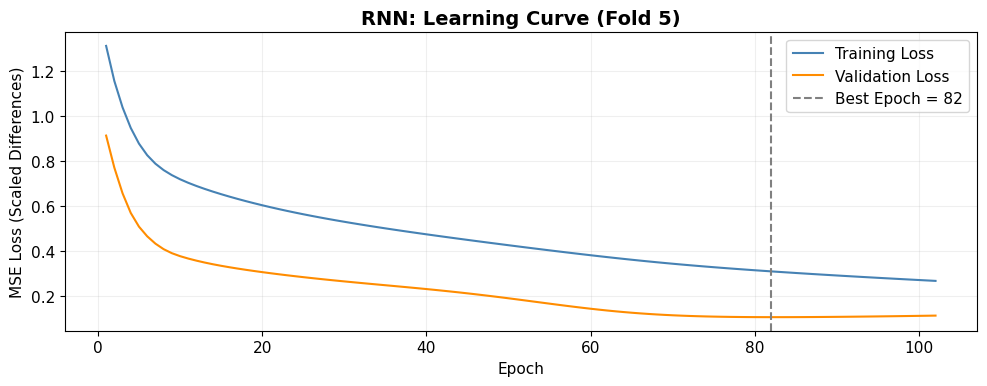

In [37]:
# 내부 학습 및 검증 손실 그래프
plot_learning_curve(
    rnn_histories,
    model_name='RNN',
    fold=5
)

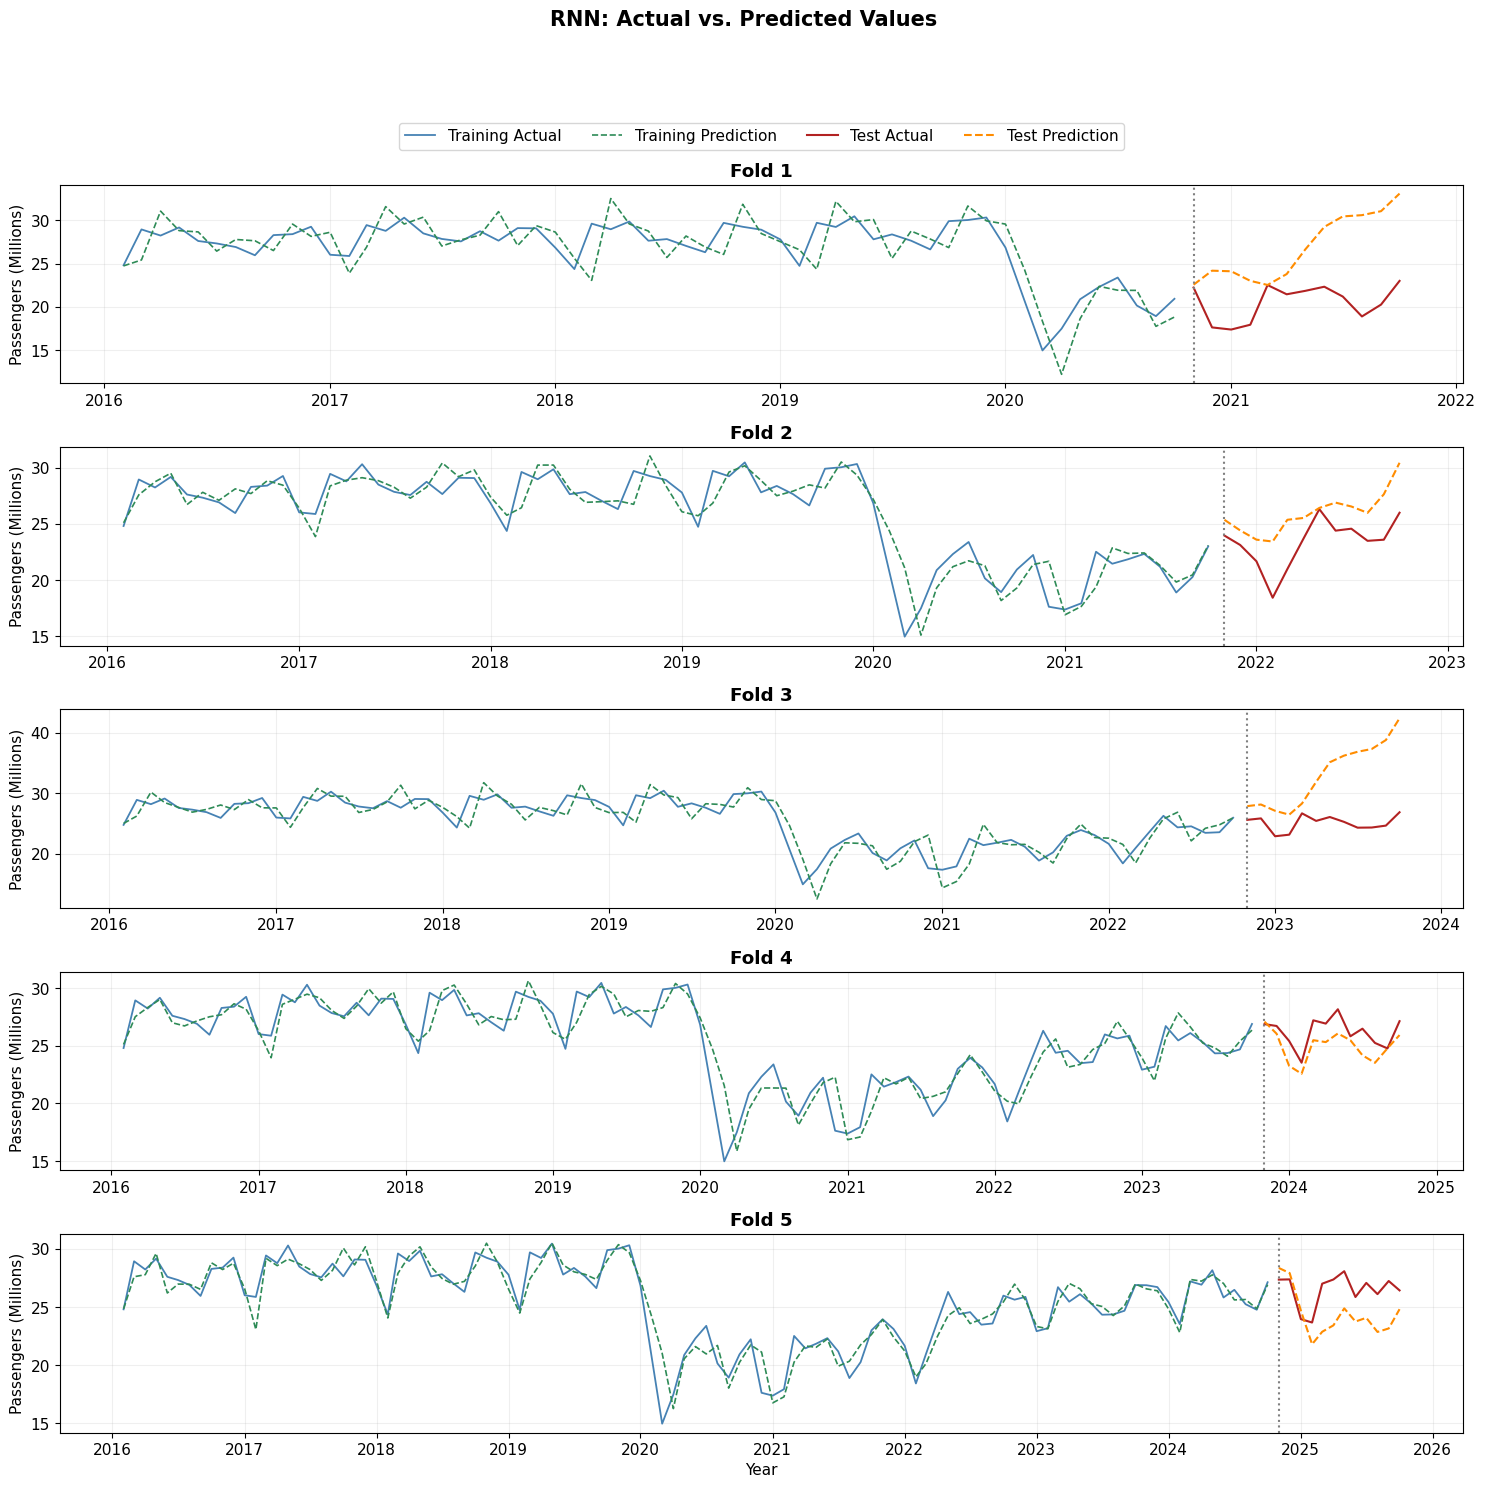

In [38]:
# Fold별 실제값 및 예측값 비교
plot_predictions(
    rnn_predictions,
    model_name='RNN'
)

#### Interpretation

Fold 5의 최적 학습 횟수는 82 Epoch로 나타났다.
Fold 1과 Fold 3에서는 각각 약 724만 명과 936만 명의
높은 Test RMSE가 관찰되었다.

단순한 순환 구조는 학습 부담을 줄일 수 있으나
복잡한 시간적 의존성을 충분히 표현하지 못할 가능성이 있다.

특히 재귀적 예측 과정에서 발생하는 오차의 전파는
RNN의 장기 예측 성능을 제한하는 요인이 될 수 있다.

### 5.6 Convolutional Neural Network (CNN)

#### 5.6.1 Model Architecture

1D-CNN은 합성곱 연산을 통해 시계열의 인접한 관측값 사이에
존재하는 국소적인 패턴과 특징을 추출한다.

합성곱 연산은 다음과 같이 표현할 수 있다.

$$
c_{t,j}=\operatorname{ReLU}
\left(\sum_{i=0}^{k-1}w_{i,j}x_{t+i}+b_j\right)
$$

$$
\operatorname{ReLU}(x)=\max(0,x)
$$

여기서 $k$는 Kernel size, $j$는 필터의 인덱스를 의미한다.

합성곱 연산을 통해 추출된 특징은 Max Pooling을 통해
압축되며, Flatten과 Dense layer를 거쳐 다음 시점의
표준화된 차분값을 예측한다.

#### 5.6.2 Model Construction

In [39]:
# CNN 모델 생성 함수
def build_cnn():

    model = keras.Sequential([
        layers.Input(shape=(LOOKBACK, 1)),

        layers.Conv1D(
            filters=16,
            kernel_size=3,
            strides=1,
            padding='valid',
            activation='relu'
        ),

        layers.MaxPooling1D(
            pool_size=2
        ),

        layers.Flatten(),

        layers.Dense(
            units=1,
            activation='linear'
        )
    ], name='CNN')

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),
        loss='mse'
    )

    return model


# 모델 구조 확인
cnn_model = build_cnn()

cnn_model.summary()

Model: "CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                      │ (None, 10, 16)              │              64 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d (MaxPooling1D)         │ (None, 5, 16)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 80)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              81 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 145 (580.00 B)

 Trainable params: 145 (580.00 B)

 Non-trainable params: 0 (0.00 B)

#### 5.6.3 Model Training and Evaluation

In [40]:
# CNN 모델의 5-Fold 학습 및 평가
cnn_results, cnn_predictions, cnn_histories = (
    train_and_evaluate(
        build_cnn,
        model_name='CNN'
    )
)

# Fold별 평가 결과
display(cnn_results)

CNN | Fold 1 completed | Best Epoch: 19 | Test RMSE: 9,721,391.22
CNN | Fold 2 completed | Best Epoch: 2 | Test RMSE: 2,998,360.97
CNN | Fold 3 completed | Best Epoch: 198 | Test RMSE: 1,306,420.38
CNN | Fold 4 completed | Best Epoch: 155 | Test RMSE: 1,526,144.24
CNN | Fold 5 completed | Best Epoch: 194 | Test RMSE: 1,500,365.92


,Model,Fold,Parameters,Best Epoch,Train RMSE,Train MAE,Test RMSE,Test MAE
0,CNN,1,145,19,"1,896,711.52","1,390,910.29","9,721,391.22","9,270,207.81"
1,CNN,2,145,2,"2,441,388.81","1,853,760.84","2,998,360.97","2,398,929.51"
2,CNN,3,145,198,"1,442,188.47","936,518.68","1,306,420.38","1,140,620.03"
3,CNN,4,145,155,"1,427,158.36","945,701.33","1,526,144.24","1,202,931.56"
4,CNN,5,145,194,"1,302,269.33","828,178.34","1,500,365.92","1,212,425.37"


In [41]:
# CNN 평균 예측 성능 및 표준편차
cnn_summary = cnn_results[
    metric_columns
].agg(['mean', 'std']).T

display(cnn_summary)

,mean,std
Train RMSE,"1,701,943.30","471,018.30"
Train MAE,"1,191,013.90","428,890.37"
Test RMSE,"3,410,536.55","3,592,484.04"
Test MAE,"3,045,022.86","3,519,546.43"


#### 5.6.4 Visualization

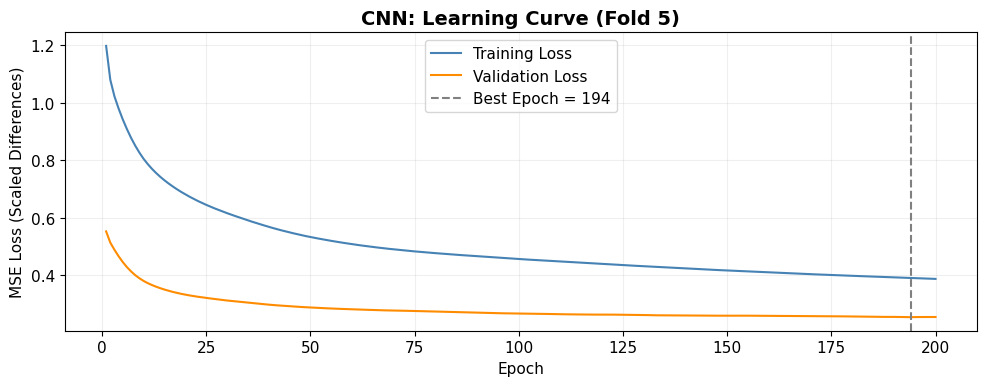

In [42]:
# 내부 학습 및 검증 손실 그래프
plot_learning_curve(
    cnn_histories,
    model_name='CNN',
    fold=5
)

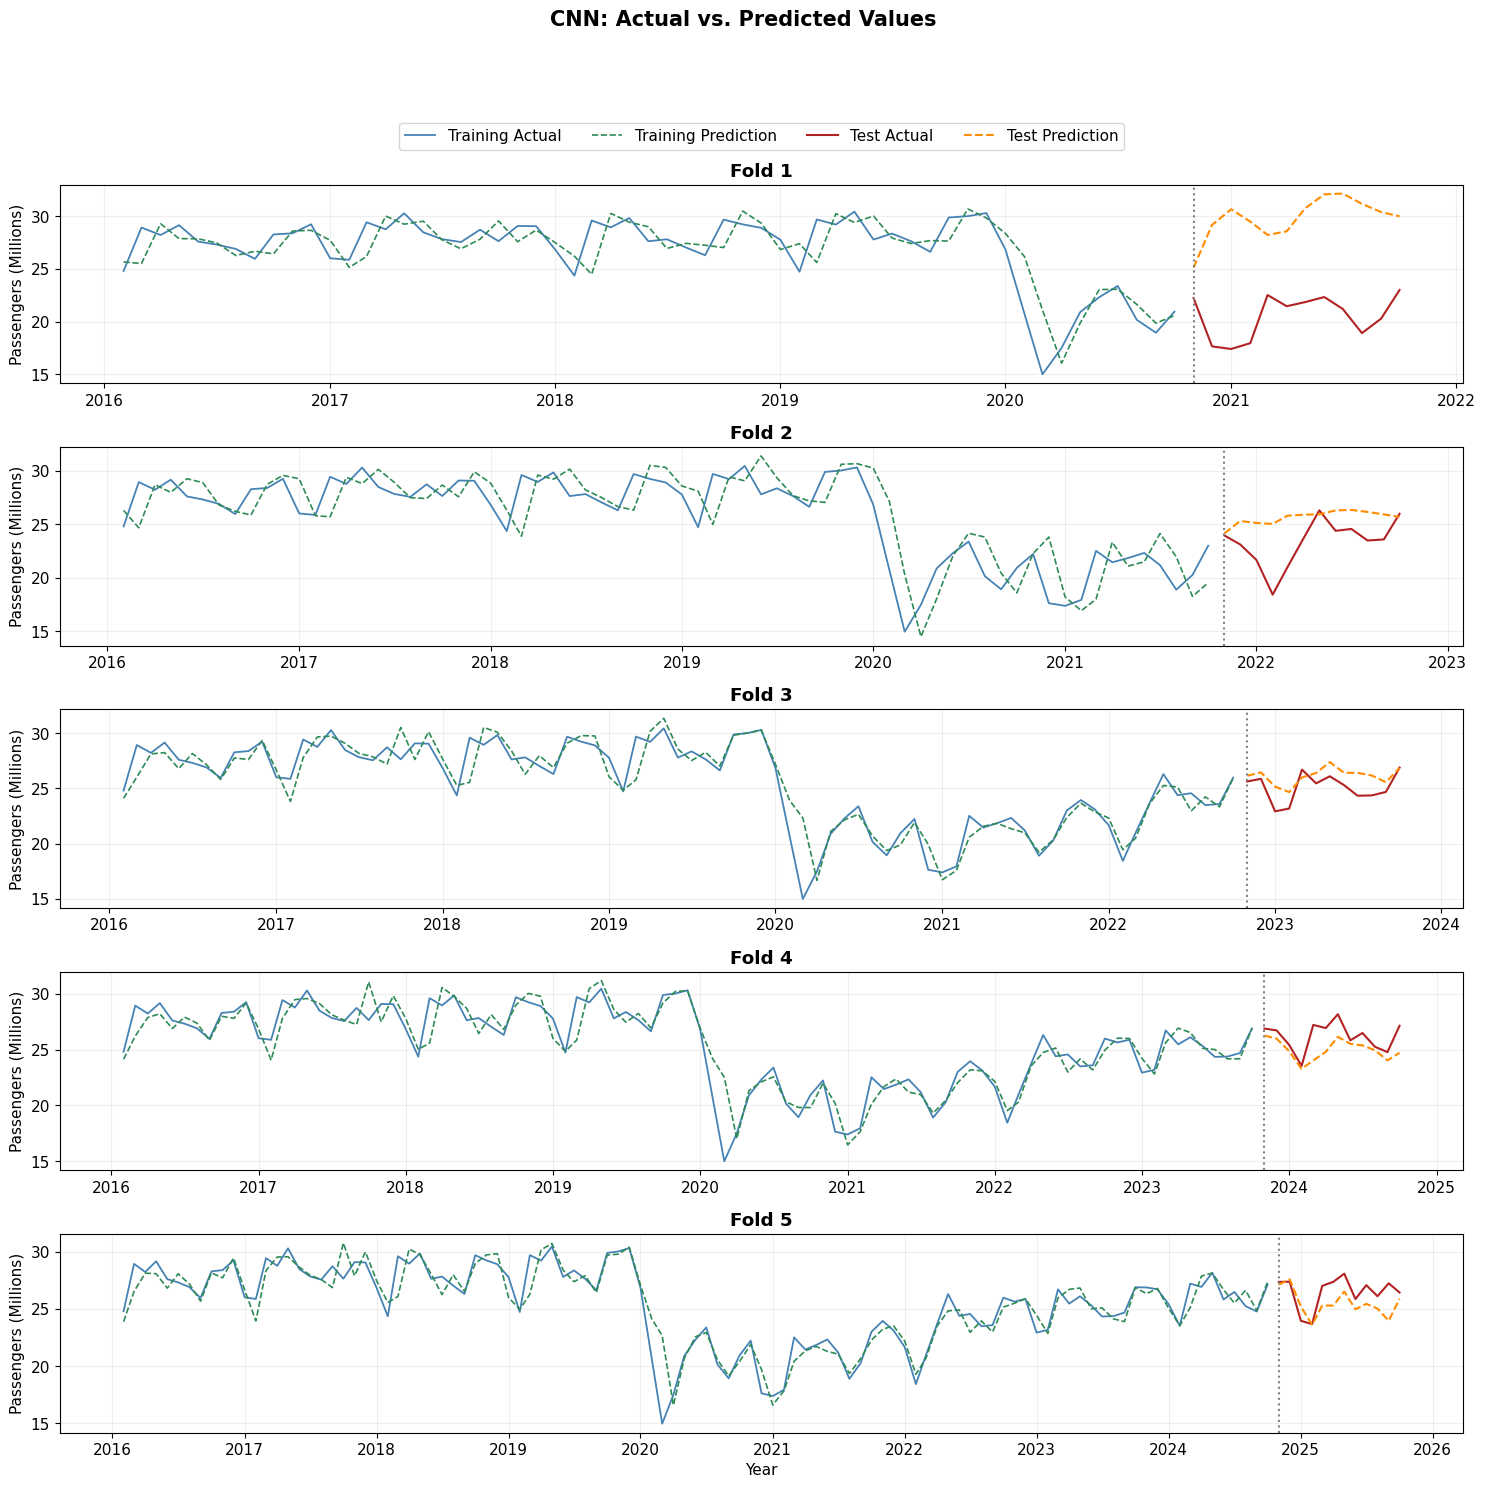

In [43]:
# Fold별 실제값 및 예측값 비교
plot_predictions(
    cnn_predictions,
    model_name='CNN'
)

#### Interpretation

CNN은 145개의 파라미터를 사용하여 비교 모델 중
가장 낮은 모델 복잡도를 나타냈다.

Fold 3~5에서는 비교적 낮은 테스트 오차가 관찰되었으나
코로나19 기간을 포함하는 Fold 1에서는 약 972만 명의
높은 Test RMSE를 기록하였다.

합성곱을 통한 국소적 특징 추출은 월별 변동을 학습하는 데
유용할 수 있지만 급격한 수준 변화와 장기적인 추세를
예측하는 데에는 한계가 있을 가능성이 있다.

Fold 5의 최적 학습 횟수는 194 Epoch로
설정한 최대 학습 횟수인 200에 근접하였다.

### 5.7 Long Short-Term Memory (LSTM)

#### 5.7.1 Model Architecture

LSTM은 RNN의 기울기 소실 문제를 완화하고 장기적인
시간 의존성을 학습하기 위해 설계된 순환신경망이다.

Forget Gate, Input Gate, Output Gate를 이용하여
정보의 유지, 갱신 및 출력을 제어한다.

각 Gate와 Cell State는 다음과 같이 정의된다.

**Forget Gate**

$$
f_t=\sigma(W_f x_t+U_f h_{t-1}+b_f)
$$

**Input Gate**

$$
i_t=\sigma(W_i x_t+U_i h_{t-1}+b_i)
$$

**Candidate Cell State**

$$
\tilde{C}_t=\tanh(W_c x_t+U_c h_{t-1}+b_c)
$$

**Cell State**

$$
C_t=f_t\odot C_{t-1}+i_t\odot\tilde{C}_t
$$

**Output Gate**

$$
o_t=\sigma(W_o x_t+U_o h_{t-1}+b_o)
$$

**Hidden State**

$$
h_t=o_t\odot\tanh(C_t)
$$

여기서 $\sigma$는 Sigmoid 함수, $\odot$는 원소별 곱을
의미한다.

최종 은닉 상태는 Dense layer를 통해 다음 시점의
표준화된 차분값을 예측하는 데 사용된다.

$$
\hat{z}_{t+1}=W_{hy}h_t+b_y
$$

#### 5.7.2 Model Construction

In [44]:
# LSTM 모델 생성 함수
def build_lstm():

    model = keras.Sequential([
        layers.Input(shape=(LOOKBACK, 1)),

        layers.LSTM(
            units=16,
            activation='tanh',
            recurrent_activation='sigmoid',
            return_sequences=False
        ),

        layers.Dense(
            units=1,
            activation='linear'
        )
    ], name='LSTM')

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),
        loss='mse'
    )

    return model


# 모델 구조 확인
lstm_model = build_lstm()

lstm_model.summary()

Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 16)                  │           1,152 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,169 (4.57 KB)

 Trainable params: 1,169 (4.57 KB)

 Non-trainable params: 0 (0.00 B)

#### 5.7.3 Model Training and Evaluation

In [45]:
# LSTM 모델의 5-Fold 학습 및 평가
lstm_results, lstm_predictions, lstm_histories = (
    train_and_evaluate(
        build_lstm,
        model_name='LSTM'
    )
)

# Fold별 평가 결과
display(lstm_results)

LSTM | Fold 1 completed | Best Epoch: 1 | Test RMSE: 2,064,786.58
LSTM | Fold 2 completed | Best Epoch: 58 | Test RMSE: 2,898,231.26
LSTM | Fold 3 completed | Best Epoch: 46 | Test RMSE: 2,817,911.43
LSTM | Fold 4 completed | Best Epoch: 106 | Test RMSE: 1,594,481.26
LSTM | Fold 5 completed | Best Epoch: 25 | Test RMSE: 1,267,176.93


,Model,Fold,Parameters,Best Epoch,Train RMSE,Train MAE,Test RMSE,Test MAE
0,LSTM,1,1169,1,"2,306,941.56","1,737,030.34","2,064,786.58","1,852,117.24"
1,LSTM,2,1169,58,"1,743,847.25","1,285,876.27","2,898,231.26","2,620,154.33"
2,LSTM,3,1169,46,"1,740,980.44","1,290,926.52","2,817,911.43","2,590,921.95"
3,LSTM,4,1169,106,"1,353,479.11","1,003,968.15","1,594,481.26","1,392,764.81"
4,LSTM,5,1169,25,"1,751,314.08","1,311,804.03","1,267,176.93","951,667.69"


In [46]:
# LSTM 평균 예측 성능 및 표준편차
lstm_summary = lstm_results[
    metric_columns
].agg(['mean', 'std']).T

display(lstm_summary)

,mean,std
Train RMSE,"1,779,312.49","340,307.78"
Train MAE,"1,325,921.06","262,531.91"
Test RMSE,"2,128,517.49","724,376.83"
Test MAE,"1,881,525.20","733,689.87"


#### 5.7.4 Visualization

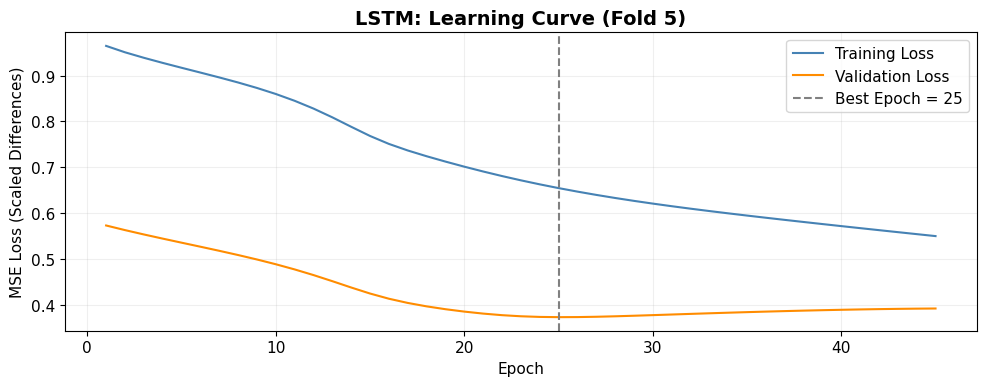

In [47]:
# 내부 학습 및 검증 손실 그래프
plot_learning_curve(
    lstm_histories,
    model_name='LSTM',
    fold=5
)

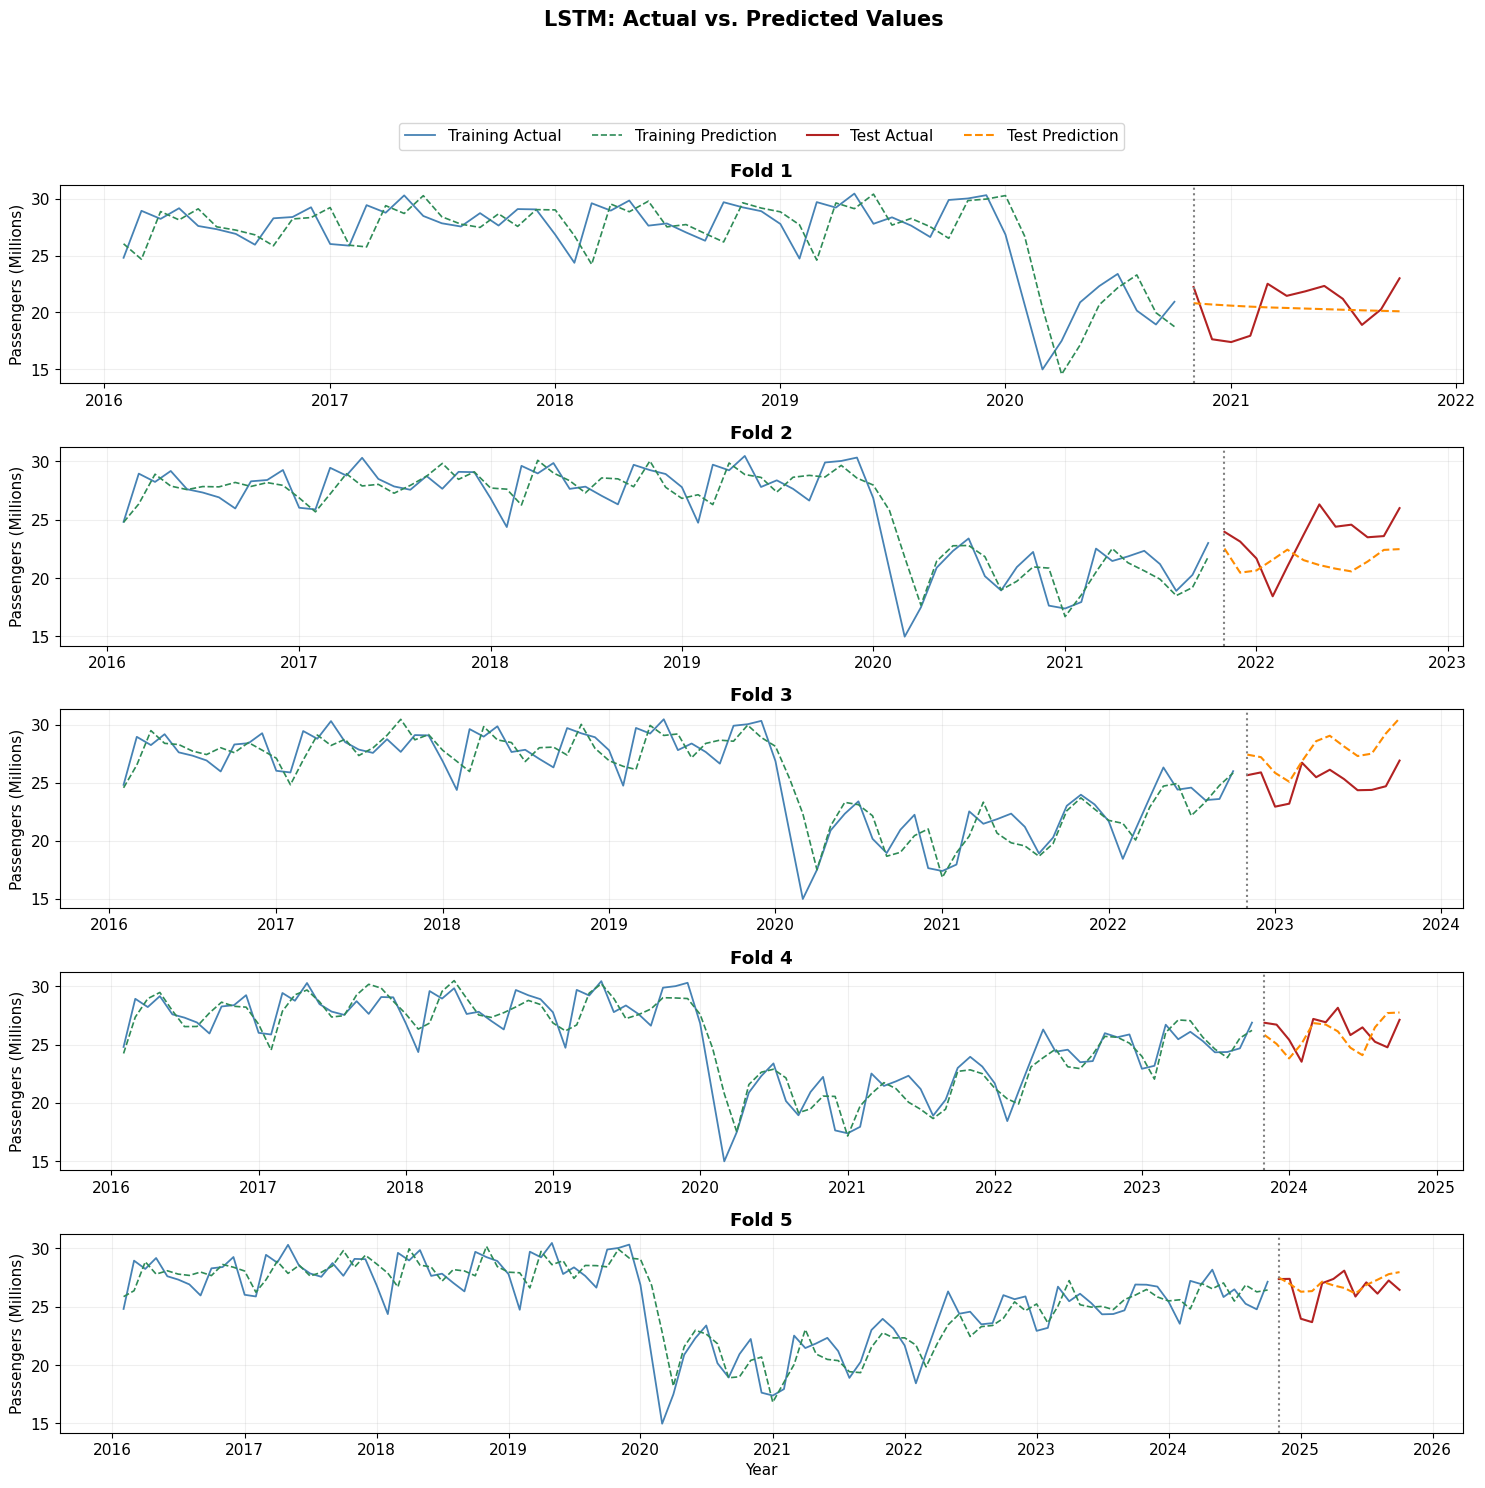

In [48]:
# Fold별 실제값 및 예측값 비교
plot_predictions(
    lstm_predictions,
    model_name='LSTM'
)

#### Interpretation

LSTM은 비교 모델 중 Test RMSE의 Fold별 표준편차가
가장 작아 상대적으로 안정적인 예측 성능을 나타냈다.

다만 일부 구간에서는 실제 승객 수의 세부적인 변동을
충분히 재현하지 못하였다.

특히 Fold 1에서는 최적 학습 횟수가 1 Epoch로
선정되었으므로 제한적인 학습 과정에서 시간적 패턴을
충분히 학습하지 못했을 가능성을 고려할 수 있다.

Fold 5의 최적 학습 횟수는 25 Epoch로 나타났다.

### 5.8 CNN-LSTM (Hybrid Model)

#### 5.8.1 Model Architecture

CNN-LSTM은 CNN의 국소적 특징 추출 능력과 LSTM의
시간적 의존성 학습 능력을 결합한 Hybrid Model이다.

1D-CNN을 통해 입력 시계열의 국소적인 패턴을 추출하고,
Max Pooling을 통해 특징의 차원을 축소한다.

$$
\mathbf{C}=\operatorname{ReLU}
(\operatorname{Conv1D}(\mathbf{X}))
$$

$$
\mathbf{P}=\operatorname{MaxPooling1D}(\mathbf{C})
$$

추출된 Feature Map은 Flatten을 적용하지 않고
시퀀스 형태를 유지한 상태에서 LSTM의 입력으로 사용한다.

$$
\mathbf{h}=\operatorname{LSTM}(\mathbf{P})
$$

최종 은닉 상태는 Dense layer를 통해 다음 시점의
표준화된 차분값을 예측하는 데 사용된다.

$$
\hat{z}_{t+1}=W_{hy}\mathbf{h}+b_y
$$

#### 5.8.2 Model Construction

In [49]:
# CNN-LSTM 모델 생성 함수
def build_cnn_lstm():

    model = keras.Sequential([
        layers.Input(shape=(LOOKBACK, 1)),

        layers.Conv1D(
            filters=16,
            kernel_size=3,
            strides=1,
            padding='valid',
            activation='relu'
        ),

        layers.MaxPooling1D(
            pool_size=2
        ),

        layers.LSTM(
            units=16,
            activation='tanh',
            recurrent_activation='sigmoid',
            return_sequences=False
        ),

        layers.Dense(
            units=1,
            activation='linear'
        )
    ], name='CNN-LSTM')

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),
        loss='mse'
    )

    return model


# 모델 구조 확인
cnn_lstm_model = build_cnn_lstm()

cnn_lstm_model.summary()

Model: "CNN-LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                      │ (None, 10, 16)              │              64 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d (MaxPooling1D)         │ (None, 5, 16)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 16)                  │           2,112 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,193 (8.57 KB)

 Trainable params: 2,193 (8.57 KB)

 Non-trainable params: 0 (0.00 B)

#### 5.8.3 Model Training and Evaluation

In [50]:
# CNN-LSTM 모델의 5-Fold 학습 및 평가
cnn_lstm_results, cnn_lstm_predictions, cnn_lstm_histories = (
    train_and_evaluate(
        build_cnn_lstm,
        model_name='CNN-LSTM'
    )
)

# Fold별 평가 결과
display(cnn_lstm_results)

CNN-LSTM | Fold 1 completed | Best Epoch: 12 | Test RMSE: 2,887,895.67
CNN-LSTM | Fold 2 completed | Best Epoch: 6 | Test RMSE: 2,570,238.12
CNN-LSTM | Fold 3 completed | Best Epoch: 67 | Test RMSE: 766,053.38
CNN-LSTM | Fold 4 completed | Best Epoch: 66 | Test RMSE: 1,208,442.59
CNN-LSTM | Fold 5 completed | Best Epoch: 116 | Test RMSE: 1,177,873.77


,Model,Fold,Parameters,Best Epoch,Train RMSE,Train MAE,Test RMSE,Test MAE
0,CNN-LSTM,1,2193,12,"2,122,403.68","1,539,232.05","2,887,895.67","2,034,566.47"
1,CNN-LSTM,2,2193,6,"2,166,366.79","1,612,749.85","2,570,238.12","2,206,574.31"
2,CNN-LSTM,3,2193,67,"1,557,085.70","1,099,493.22","766,053.38","595,679.18"
3,CNN-LSTM,4,2193,66,"1,424,546.14","1,001,172.86","1,208,442.59","1,012,785.49"
4,CNN-LSTM,5,2193,116,"985,564.56","671,685.32","1,177,873.77","902,987.83"


In [51]:
# CNN-LSTM 평균 예측 성능 및 표준편차
cnn_lstm_summary = cnn_lstm_results[
    metric_columns
].agg(['mean', 'std']).T

display(cnn_lstm_summary)

,mean,std
Train RMSE,"1,651,193.37","497,677.04"
Train MAE,"1,184,866.66","391,486.26"
Test RMSE,"1,722,100.71","942,399.74"
Test MAE,"1,350,518.66","721,956.17"


#### 5.8.4 Visualization

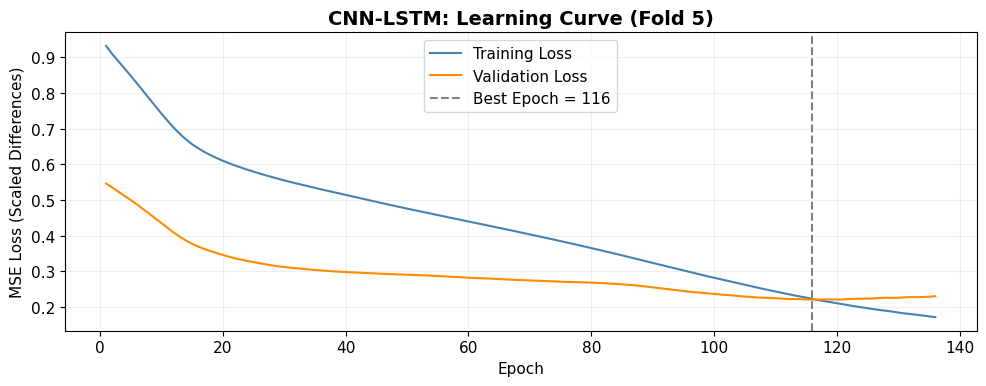

In [52]:
# 내부 학습 및 검증 손실 그래프
plot_learning_curve(
    cnn_lstm_histories,
    model_name='CNN-LSTM',
    fold=5
)

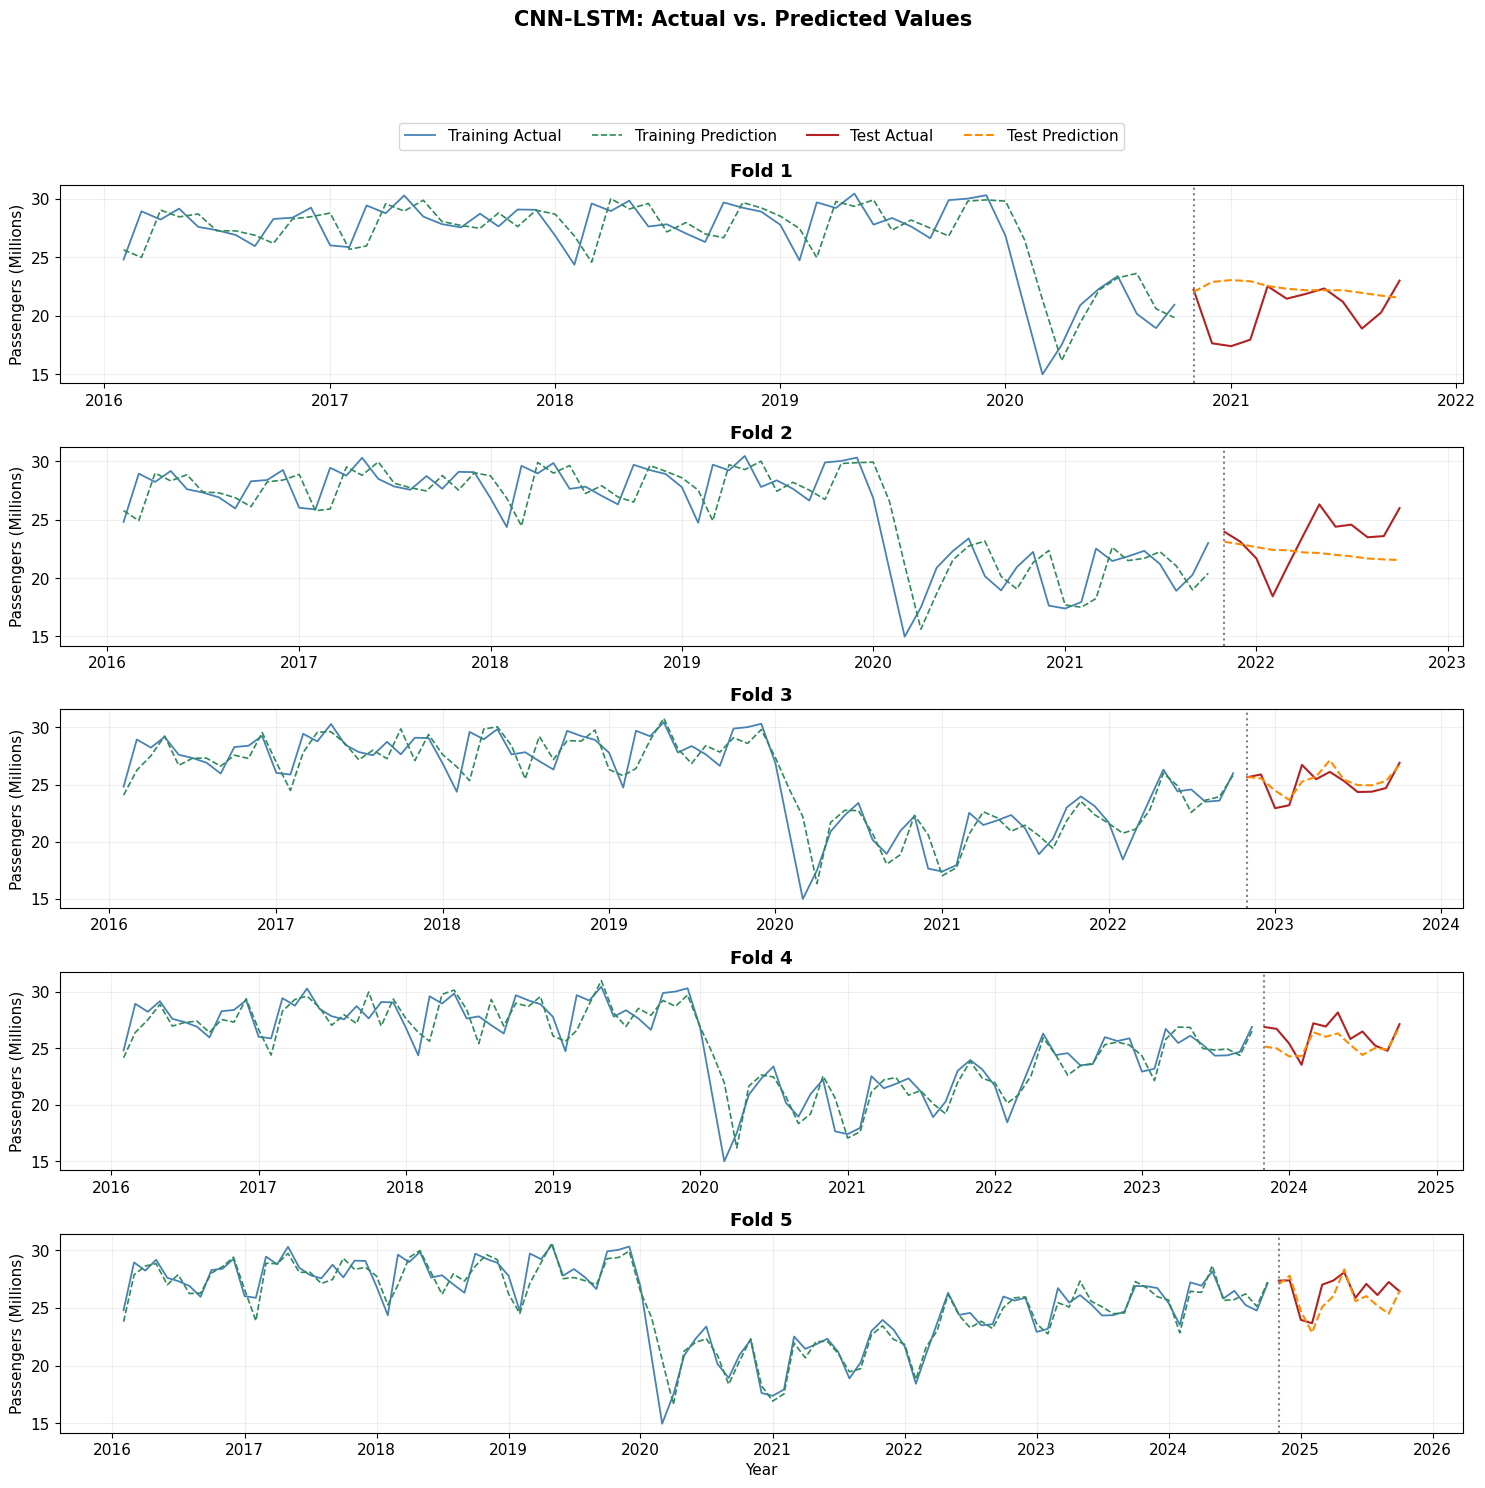

In [53]:
# Fold별 실제값 및 예측값 비교
plot_predictions(
    cnn_lstm_predictions,
    model_name='CNN-LSTM'
)

#### Interpretation

CNN-LSTM은 Fold 2~5에서 Test RMSE와 MAE가
모두 비교 모델 중 가장 낮게 나타났다.

특히 Fold 3의 Test RMSE는 약 76.6만 명으로
다른 모델보다 낮은 예측오차를 기록하였다.

이는 CNN의 국소적 특징 추출과 LSTM의 시간적
의존성 학습을 결합한 구조가 해당 자료의 예측에
유용할 가능성을 보여준다.

Fold 5의 최적 학습 횟수는 116 Epoch이며,
가장 많은 파라미터를 사용하였음에도 우수한 테스트
예측 성능을 나타냈다.

### 5.9 Transformer

#### 5.9.1 Model Architecture

Transformer는 Self-Attention Mechanism을 이용하여
입력 시퀀스 내 각 시점 간의 의존성을 학습하는 모델이다.

순환 연산 없이 서로 다른 시점 간의 관계를 직접 학습할 수
있으며, Positional Encoding을 통해 시간적 순서 정보를 반영한다.

**Scaled Dot-Product Attention**

$$
\operatorname{Attention}(Q,K,V)
=\operatorname{softmax}
\left(\frac{QK^\top}{\sqrt{d_k}}\right)V
$$

여기서 $Q$, $K$, $V$는 각각 Query, Key, Value를 의미하며,
$d_k$는 Key 벡터의 차원을 의미한다.

**Multi-Head Attention**

$$
\operatorname{head}_i=
\operatorname{Attention}(QW_i^Q,KW_i^K,VW_i^V)
$$

$$
\operatorname{MultiHead}(Q,K,V)
=\operatorname{Concat}
(\operatorname{head}_1,\ldots,\operatorname{head}_H)W^O
$$

Multi-Head Attention을 통해 서로 다른 표현 공간에서
시점 간의 의존성을 학습한다.

**Feed-Forward Network**

$$
\operatorname{FFN}(x)
=\operatorname{ReLU}(xW_1+b_1)W_2+b_2
$$

본 모델은 Decoder를 사용하지 않는 Encoder-only 구조이며,
Self-Attention, Residual Connection, Layer Normalization
및 Feed-Forward Network로 구성된다.

최종 Encoder 출력은 Global Average Pooling과 Dense layer를
거쳐 다음 시점의 표준화된 차분값을 예측한다.

#### 5.9.2 Model Construction

In [54]:
# Transformer 하이퍼파라미터
D_MODEL = 8
NUM_HEADS = 2
KEY_DIM = D_MODEL // NUM_HEADS
FF_DIM = 16

In [55]:
# 학습 가능한 위치 정보 추가
class PositionalEncoding(layers.Layer):

    def build(self, input_shape):

        self.position_embedding = self.add_weight(
            name='position_embedding',
            shape=(1, input_shape[1], input_shape[2]),
            initializer=keras.initializers.RandomNormal(
                stddev=0.02
            ),
            trainable=True
        )

    def call(self, inputs):

        return inputs + self.position_embedding

In [56]:
# Transformer 모델 생성 함수
def build_transformer():

    inputs = layers.Input(
        shape=(LOOKBACK, 1)
    )

    # 1. Input Projection
    x = layers.Dense(D_MODEL)(inputs)

    # 2. Positional Encoding
    x = PositionalEncoding()(x)

    # 3. Multi-Head Self-Attention
    attention_output = layers.MultiHeadAttention(
        num_heads=NUM_HEADS,
        key_dim=KEY_DIM
    )(x, x)

    # 4. Residual Connection & Layer Normalization
    x = layers.Add()([x, attention_output])

    x = layers.LayerNormalization(
        epsilon=1e-6
    )(x)

    # 5. Feed-Forward Network
    ffn_output = layers.Dense(
        FF_DIM,
        activation='relu'
    )(x)

    ffn_output = layers.Dense(
        D_MODEL
    )(ffn_output)

    # 6. Residual Connection & Layer Normalization
    x = layers.Add()([x, ffn_output])

    x = layers.LayerNormalization(
        epsilon=1e-6
    )(x)

    # 7. Global Average Pooling
    x = layers.GlobalAveragePooling1D()(x)

    # 8. Output Layer
    outputs = layers.Dense(
        units=1,
        activation='linear'
    )(x)

    model = keras.Model(
        inputs=inputs,
        outputs=outputs,
        name='Transformer'
    )

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),
        loss='mse'
    )

    return model


# 모델 구조 확인
transformer_model = build_transformer()

transformer_model.summary()

Model: "Transformer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)    │ (None, 12, 1)             │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_1 (Dense)               │ (None, 12, 8)             │              16 │ input_layer_1[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ positional_encoding           │ (None, 12, 8)             │              96 │ dense_1[0][0]              │
│ (PositionalEncoding)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ multi_head_attention          │ (None, 12, 8)             │             288 │ positional_encoding[0][0], │
│ (MultiHeadAttention)          │                           │                 │ positional_encoding[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add (Add)                     │ (None, 12, 8)             │               0 │ positional_encoding[0][0], │
│                               │                           │                 │ multi_head_attention[0][0] │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ layer_normalization           │ (None, 12, 8)             │              16 │ add[0][0]                  │
│ (LayerNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_2 (Dense)               │ (None, 12, 16)            │             144 │ layer_normalization[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_3 (Dense)               │ (None, 12, 8)             │             136 │ dense_2[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add_1 (Add)                   │ (None, 12, 8)             │               0 │ layer_normalization[0][0], │
│                               │                           │                 │ dense_3[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ layer_normalization_1         │ (None, 12, 8)             │              16 │ add_1[0][0]                │
│ (LayerNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ global_average_pooling1d      │ (None, 8)                 │               0 │ layer_normalization_1[0][… │
│ (GlobalAveragePooling1D)      │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_4 (Dense)               │ (None, 1)                 │               9 │ global_average_pooling1d[… │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 721 (2.82 KB)

 Trainable params: 721 (2.82 KB)

 Non-trainable params: 0 (0.00 B)

#### 5.9.3 Model Training and Evaluation

In [57]:
# Transformer 모델의 5-Fold 학습 및 평가
transformer_results, transformer_predictions, transformer_histories = (
    train_and_evaluate(
        build_transformer,
        model_name='Transformer'
    )
)

# Fold별 평가 결과
display(transformer_results)

Transformer | Fold 1 completed | Best Epoch: 4 | Test RMSE: 3,824,872.93
Transformer | Fold 2 completed | Best Epoch: 2 | Test RMSE: 2,874,109.97
Transformer | Fold 3 completed | Best Epoch: 49 | Test RMSE: 1,254,912.62
Transformer | Fold 4 completed | Best Epoch: 53 | Test RMSE: 1,561,542.24
Transformer | Fold 5 completed | Best Epoch: 114 | Test RMSE: 1,797,576.45


,Model,Fold,Parameters,Best Epoch,Train RMSE,Train MAE,Test RMSE,Test MAE
0,Transformer,1,721,4,"2,123,805.91","1,517,038.92","3,824,872.93","3,447,280.84"
1,Transformer,2,721,2,"2,270,019.27","1,726,759.58","2,874,109.97","2,567,212.14"
2,Transformer,3,721,49,"1,785,444.98","1,273,069.91","1,254,912.62","1,093,570.10"
3,Transformer,4,721,53,"1,588,991.56","1,132,658.87","1,561,542.24","1,256,539.90"
4,Transformer,5,721,114,"1,205,274.81","885,773.10","1,797,576.45","1,500,356.14"


In [58]:
# Transformer 평균 예측 성능 및 표준편차
transformer_summary = transformer_results[
    metric_columns
].agg(['mean', 'std']).T

display(transformer_summary)

,mean,std
Train RMSE,"1,794,707.31","425,459.39"
Train MAE,"1,307,060.07","327,602.13"
Test RMSE,"2,262,602.84","1,065,106.09"
Test MAE,"1,972,991.82","1,004,576.57"


#### 5.9.4 Visualization

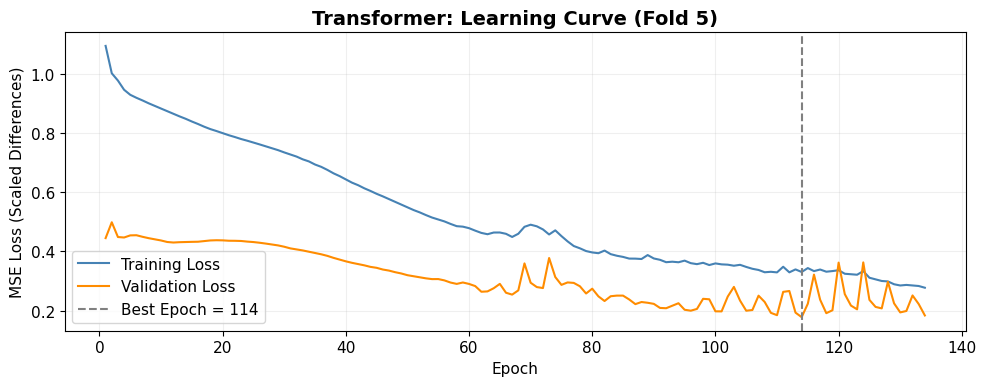

In [59]:
# 내부 학습 및 검증 손실 그래프
plot_learning_curve(
    transformer_histories,
    model_name='Transformer',
    fold=5
)

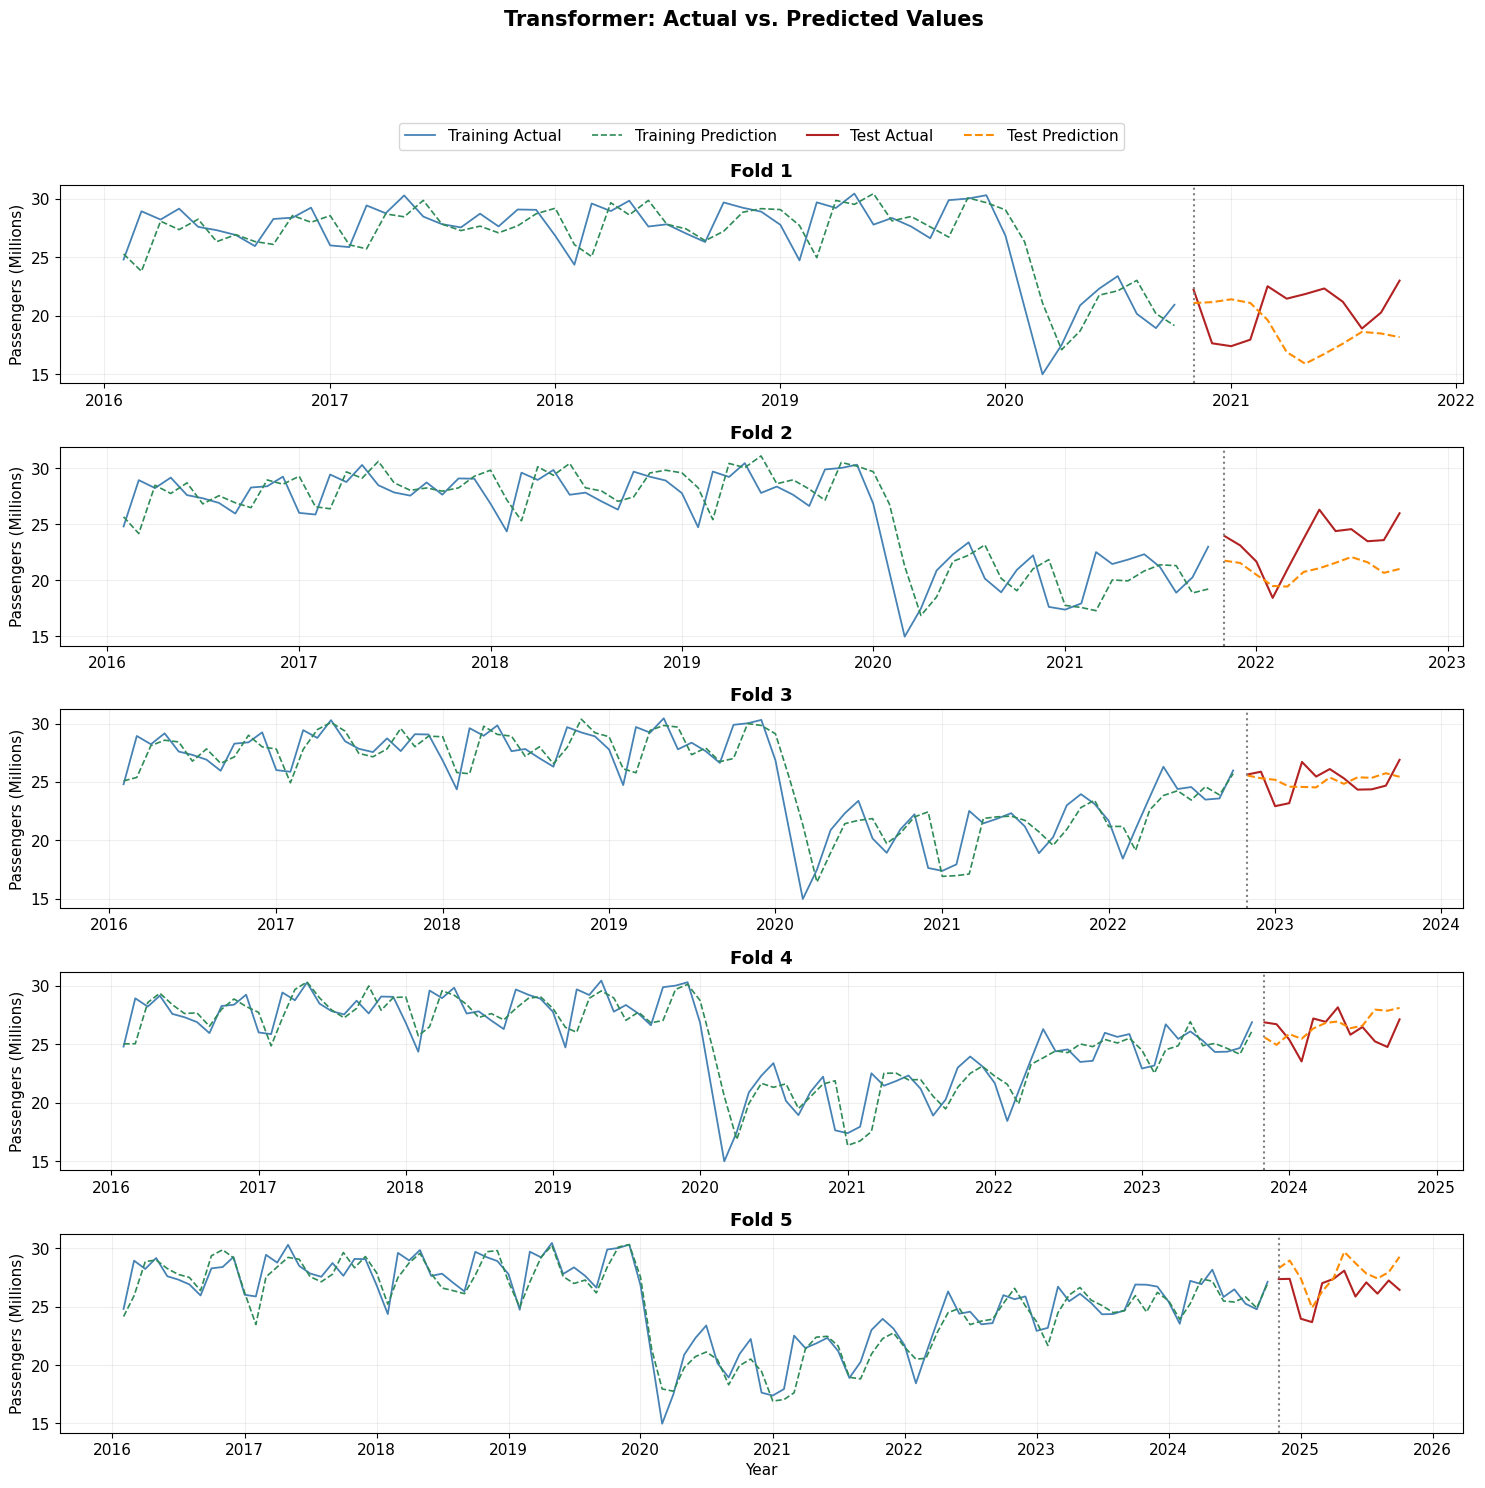

In [60]:
# Fold별 실제값 및 예측값 비교
plot_predictions(
    transformer_predictions,
    model_name='Transformer'
)

#### Interpretation

Transformer는 RNN 및 CNN보다 낮은 평균 테스트 오차를
나타냈으나 LSTM과 CNN-LSTM의 성능에는 미치지 못하였다.

Self-Attention을 통해 시점 간 의존성을 직접 학습할 수
있지만 제한적인 표본 수와 작은 표현 차원은 복잡한
시간적 패턴의 학습을 제한할 가능성이 있다.

또한 Global Average Pooling 과정에서 시점별 세부
정보가 약화될 수 있다.

Fold 5의 최적 학습 횟수는 114 Epoch로 나타났다.

## 6. Model Performance Comparison

### 6.1 Overall Performance

Train 성능은 학습 구간 내 1-Step Prediction을 기준으로,
Test 성능은 12개월 Recursive Forecasting을 기준으로 평가한다.

각 평가 지표의 평균과 표준편차는 5개 Fold에서 산출한
평가 지표를 기준으로 계산한다.

Train과 Test의 예측오차 차이에는 일반화 성능뿐만 아니라
예측 방식 및 오차 누적의 차이가 반영될 수 있다.

In [61]:
# 모델별 평가 결과 통합
all_results = pd.concat([
    rnn_results,
    cnn_results,
    lstm_results,
    cnn_lstm_results,
    transformer_results
], ignore_index=True)

# 모델 순서 지정
model_order = [
    'RNN',
    'CNN',
    'LSTM',
    'CNN-LSTM',
    'Transformer'
]

# 모델별 평균 예측 성능
mean_performance = (
    all_results
    .groupby('Model')[metric_columns]
    .mean()
    .reindex(model_order)
)

# 모델별 예측 성능의 표준편차
std_performance = (
    all_results
    .groupby('Model')[metric_columns]
    .std()
    .reindex(model_order)
)

# 백만 명 단위로 변환
mean_performance_m = mean_performance / 1e6
std_performance_m = std_performance / 1e6

In [62]:
# Mean ± SD 형태의 결과표 생성
performance_table = pd.DataFrame(
    index=model_order
)

for metric in metric_columns:

    performance_table[metric] = [
        f'{mean:.3f} ± {std:.3f}'
        for mean, std in zip(
            mean_performance_m[metric],
            std_performance_m[metric]
        )
    ]

performance_table.index.name = 'Model'

print('Mean ± SD across 5 folds (Unit: Million passengers)')

best_mask = mean_performance_m.eq(
    mean_performance_m.min(axis=0),
    axis=1
)

display(
    performance_table.style.apply(
        lambda _: best_mask.replace({
            True: 'font-weight: bold;',
            False: ''
        }),
        axis=None
    )
)

Mean ± SD across 5 folds (Unit: Million passengers)


,Train RMSE,Train MAE,Test RMSE,Test MAE
Model,,,,
RNN,1.732 ± 0.473,1.308 ± 0.451,4.763 ± 3.366,4.093 ± 2.839
CNN,1.702 ± 0.471,1.191 ± 0.429,3.411 ± 3.592,3.045 ± 3.520
LSTM,1.779 ± 0.340,1.326 ± 0.263,2.129 ± 0.724,1.882 ± 0.734
CNN-LSTM,1.651 ± 0.498,1.185 ± 0.391,1.722 ± 0.942,1.351 ± 0.722
Transformer,1.795 ± 0.425,1.307 ± 0.328,2.263 ± 1.065,1.973 ± 1.005


### 6.2 Performance Visualization

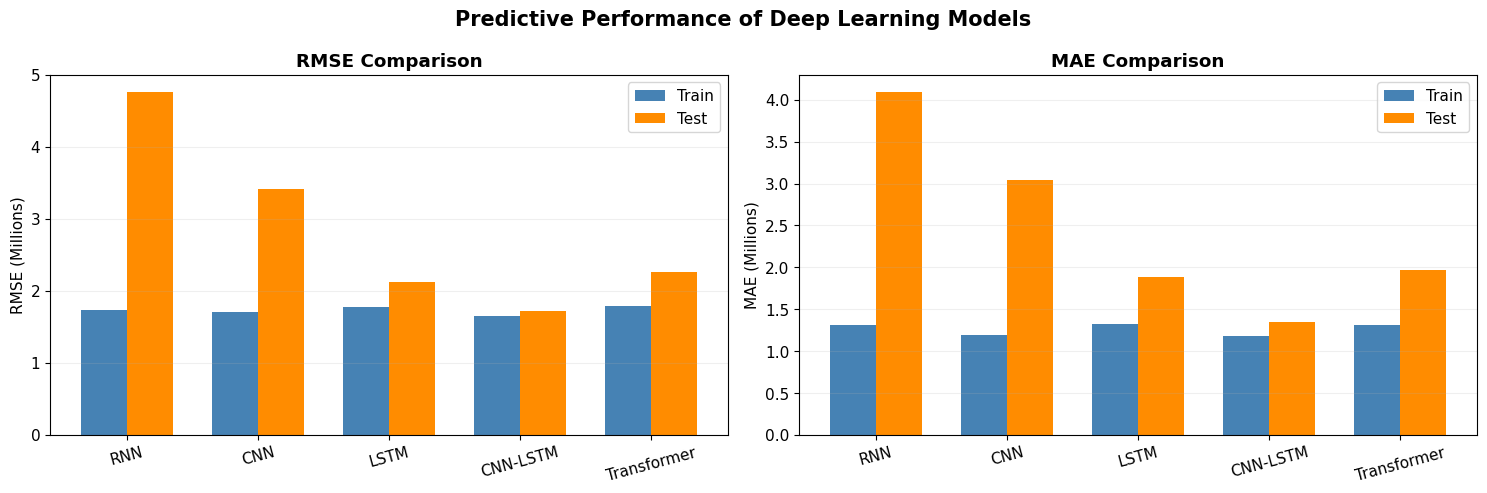

In [63]:
# RMSE 및 MAE 비교 그래프
fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5)
)

x = np.arange(len(model_order))
width = 0.35

for ax, metric in zip(axes, ['RMSE', 'MAE']):

    # Training 성능
    ax.bar(
        x - width / 2,
        mean_performance_m[f'Train {metric}'],
        width,
        color='steelblue',
        label='Train'
    )

    # Test 성능
    ax.bar(
        x + width / 2,
        mean_performance_m[f'Test {metric}'],
        width,
        color='darkorange',
        label='Test'
    )

    ax.set_title(
        f'{metric} Comparison',
        fontweight='bold'
    )

    ax.set_xticks(x)
    ax.set_xticklabels(model_order, rotation=15)

    ax.set_ylabel(f'{metric} (Millions)')
    ax.legend()
    ax.grid(axis='y', alpha=0.2)

fig.suptitle(
    'Predictive Performance of Deep Learning Models',
    fontsize=15,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

### 6.3 Fold-wise Performance

In [64]:
# Fold별 Test RMSE
fold_rmse = all_results.pivot(
    index='Fold',
    columns='Model',
    values='Test RMSE'
)[model_order] / 1e6

# Fold별 Test MAE
fold_mae = all_results.pivot(
    index='Fold',
    columns='Model',
    values='Test MAE'
)[model_order] / 1e6

print('Test RMSE (Millions)')

display(
    fold_rmse.style
    .format('{:.3f}')
    .highlight_min(
        axis=1,
        props='font-weight: bold;'
    )
)

print('Test MAE (Millions)')

display(
    fold_mae.style
    .format('{:.3f}')
    .highlight_min(
        axis=1,
        props='font-weight: bold;'
    )
)

Test RMSE (Millions)


Model,RNN,CNN,LSTM,CNN-LSTM,Transformer
Fold,,,,,
1,7.240,9.721,2.065,2.888,3.825
2,2.985,2.998,2.898,2.570,2.874
3,9.362,1.306,2.818,0.766,1.255
4,1.469,1.526,1.594,1.208,1.562
5,2.760,1.500,1.267,1.178,1.798


Test MAE (Millions)


Model,RNN,CNN,LSTM,CNN-LSTM,Transformer
Fold,,,,,
1,6.204,9.270,1.852,2.035,3.447
2,2.611,2.399,2.620,2.207,2.567
3,7.944,1.141,2.591,0.596,1.094
4,1.251,1.203,1.393,1.013,1.257
5,2.456,1.212,0.952,0.903,1.500


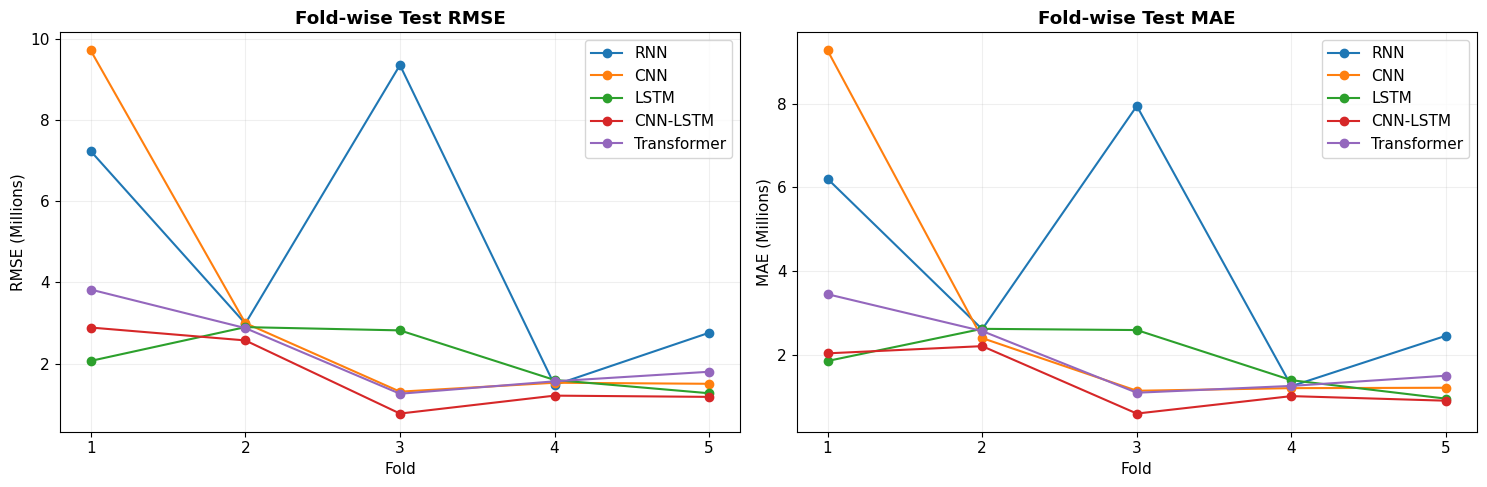

In [65]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5)
)

for ax, data, metric in zip(
    axes,
    [fold_rmse, fold_mae],
    ['RMSE', 'MAE']
):

    for model in model_order:

        ax.plot(
            data.index,
            data[model],
            marker='o',
            linewidth=1.5,
            label=model
        )

    ax.set_title(
        f'Fold-wise Test {metric}',
        fontweight='bold'
    )

    ax.set_xlabel('Fold')
    ax.set_ylabel(f'{metric} (Millions)')
    ax.set_xticks(range(1, 6))
    ax.grid(alpha=0.2)
    ax.legend()

plt.tight_layout()
plt.show()

### 6.4 Model Complexity

In [66]:
# 모델별 파라미터 수
model_parameters = (
    all_results
    .groupby('Model')['Parameters']
    .first()
    .reindex(model_order)
)

# 모델 복잡도 및 예측 성능 비교
complexity_table = pd.DataFrame({
    'Parameters': model_parameters,
    'Test RMSE': mean_performance_m['Test RMSE'],
    'Test RMSE SD': std_performance_m['Test RMSE']
})

display(
    complexity_table.style.format({
        'Parameters': '{:,}',
        'Test RMSE': '{:.3f}',
        'Test RMSE SD': '{:.3f}'
    })
)

,Parameters,Test RMSE,Test RMSE SD
Model,,,
RNN,305,4.763,3.366
CNN,145,3.411,3.592
LSTM,"1,169",2.129,0.724
CNN-LSTM,"2,193",1.722,0.942
Transformer,721,2.263,1.065


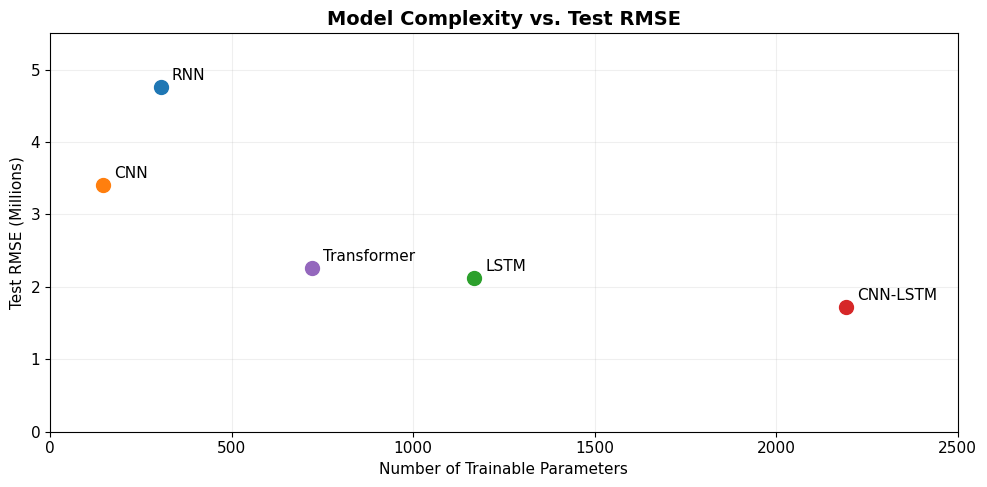

In [67]:
fig, ax = plt.subplots(figsize=(10, 5))

for model in model_order:

    params = complexity_table.loc[model, 'Parameters']
    rmse = complexity_table.loc[model, 'Test RMSE']

    ax.scatter(
        params,
        rmse,
        s=100
    )

    ax.annotate(
        model,
        (params, rmse),
        xytext=(8, 5),
        textcoords='offset points'
    )

ax.set_title(
    'Model Complexity vs. Test RMSE',
    fontsize=14,
    fontweight='bold'
)

ax.set_xlabel('Number of Trainable Parameters')
ax.set_ylabel('Test RMSE (Millions)')

# 축 범위 및 눈금 설정
ax.set_xlim(0, 2500)
ax.set_ylim(0, 5.5)

ax.set_xticks(np.arange(0, 2501, 500))
ax.set_yticks(np.arange(0, 6, 1))

ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

#### Interpretation

가장 많은 파라미터를 사용하는 CNN-LSTM이 가장 낮은
평균 Test RMSE를 나타냈다.

반면 CNN은 가장 적은 파라미터를 사용하였음에도
RNN보다 우수한 평균 예측 성능을 기록하였다.

이는 파라미터 수뿐만 아니라 모델의 구조와 특징 추출
방식도 예측 성능을 고려할 때 중요한 요소임을 시사한다.

다만 모델별 구조와 초모수 설정이 서로 다르므로
파라미터 수와 예측 성능 사이의 인과관계를
확정할 수는 없다.

### 6.5 Hyperparameter Comparison

In [68]:
# 모델별 주요 초모수 비교
hyperparameter_table = pd.DataFrame({
    'RNN': [16, '-', '-', '-', '-', '-', '-'],
    'CNN': ['-', 16, 3, 2, '-', '-', '-'],
    'LSTM': [16, '-', '-', '-', '-', '-', '-'],
    'CNN-LSTM': [16, 16, 3, 2, '-', '-', '-'],
    'Transformer': ['-', '-', '-', '-', 8, 2, 16]
}, index=[
    'Hidden units',
    'CNN filters',
    'Kernel size',
    'Pool size',
    'Embedding dimension',
    'Attention heads',
    'FFN dimension'
]).T

# 모델별 파라미터 수 추가
hyperparameter_table['Parameters'] = model_parameters

display(hyperparameter_table)

,Hidden units,CNN filters,Kernel size,Pool size,Embedding dimension,Attention heads,FFN dimension,Parameters
RNN,16,-,-,-,-,-,-,305
CNN,-,16,3,2,-,-,-,145
LSTM,16,-,-,-,-,-,-,1169
CNN-LSTM,16,16,3,2,-,-,-,2193
Transformer,-,-,-,-,8,2,16,721


### 6.6 Best Model Selection

In [69]:
# 테스트 성능에 따른 모델 순위
model_ranking = mean_performance_m[
    ['Test RMSE', 'Test MAE']
].sort_values(
    by=['Test RMSE', 'Test MAE']
)

model_ranking.insert(
    0,
    'Rank',
    np.arange(1, len(model_ranking) + 1)
)

display(
    model_ranking.style.format({
        'Test RMSE': '{:.3f}',
        'Test MAE': '{:.3f}'
    })
)

# 최적 모델 선정
best_model_name = model_ranking.index[0]

print('Best Model:', best_model_name)

,Rank,Test RMSE,Test MAE
Model,,,
CNN-LSTM,1,1.722,1.351
LSTM,2,2.129,1.882
Transformer,3,2.263,1.973
CNN,4,3.411,3.045
RNN,5,4.763,4.093


Best Model: CNN-LSTM


5-Fold Time-Series Cross-Validation 결과, 평균 Test RMSE와
MAE가 가장 낮은 CNN-LSTM을 최종 예측 모델로 선정하였다.
전체 관측 데이터를 이용하여 모델을 재학습한 후
향후 24개월의 승객 수를 예측한다.

## 7. Future Forecasting

### 7.1 Final Model Training

In [70]:
# 전체 관측 데이터에 1차 차분 적용
final_diff = ts.diff().dropna()

# 전체 관측 데이터 기준 표준화
final_scaler = StandardScaler()

final_scaled = final_scaler.fit_transform(
    final_diff.to_numpy().reshape(-1, 1)
)

# 최종 학습 시퀀스 생성
X_final, y_final = create_sequences(
    final_scaled,
    LOOKBACK
)

print('Training period:',
      ts.index[0].strftime('%Y-%m'), '~',
      ts.index[-1].strftime('%Y-%m'))

print('X_final shape:', X_final.shape)
print('y_final shape:', y_final.shape)

Training period: 2015-01 ~ 2025-10
X_final shape: (117, 12, 1)
y_final shape: (117,)


In [71]:
# 전체 데이터의 내부 검증 시퀀스 생성
X_inner, y_inner, X_val, y_val = (
    prepare_validation_data(ts)
)

# 모델 초기화
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

final_validation_model = build_cnn_lstm()

# 내부 검증 및 Early Stopping
final_history = final_validation_model.fit(
    X_inner,
    y_inner,
    validation_data=(X_val, y_val),
    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[create_early_stopping()],
    shuffle=False,
    verbose=0
)

# 최적 학습 횟수 선정
final_best_epoch = int(
    np.argmin(final_history.history['val_loss']) + 1
)

print('Best Epoch:', final_best_epoch)

Best Epoch: 115


In [72]:
# 최종 모델 초기화
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

final_model = build_cnn_lstm()

# 전체 관측 데이터로 재학습
final_model.fit(
    X_final,
    y_final,
    epochs=final_best_epoch,
    batch_size=BATCH_SIZE,
    shuffle=False,
    verbose=0
)

print('Final Model:', best_model_name)
print('Training Samples:', len(X_final))
print('Training Epochs:', final_best_epoch)
print('Final model training completed.')

Final Model: CNN-LSTM
Training Samples: 117
Training Epochs: 115
Final model training completed.


### 7.2 24-Month Forecasting

전체 학습 데이터의 마지막 12개 표준화 차분값을
초기 입력 시퀀스로 사용하여 향후 24개월을 예측한다.

Recursive Forecasting을 통해 예측값을 순차적으로 생성하고,
표준화 및 차분의 역변환을 통해 원래 승객 수 단위로 복원한다.

In [73]:
# 미래 예측 기간
FORECAST_HORIZON = 24

# 마지막 12개 표준화 차분값
initial_sequence = final_scaled[-LOOKBACK:]

# 재귀적 다단계 예측
future_scaled = recursive_forecast(
    final_model,
    initial_sequence,
    steps=FORECAST_HORIZON
)

# 표준화 및 차분 역변환
future_pred = inverse_forecast(
    future_scaled,
    final_scaler,
    last_actual=ts.iloc[-1]
)

# 미래 예측 날짜 생성
future_dates = pd.date_range(
    start=ts.index[-1] + pd.offsets.MonthBegin(1),
    periods=FORECAST_HORIZON,
    freq='MS'
)

# 미래 예측 결과 저장
future_forecast = pd.Series(
    future_pred,
    index=future_dates,
    name='Forecast'
)

print('Forecast Start:',
      future_forecast.index[0].strftime('%Y-%m'))

print('Forecast End:',
      future_forecast.index[-1].strftime('%Y-%m'))

print('Forecast Periods:', len(future_forecast))

Forecast Start: 2025-11
Forecast End: 2027-10
Forecast Periods: 24


In [74]:
# 월별 예측 결과표
forecast_table = pd.DataFrame({
    'Month': future_forecast.index.strftime('%Y-%m'),
    'Forecasted Passengers': future_forecast.values
})

display(
    forecast_table.style
    .hide(axis='index')
    .format({
        'Forecasted Passengers': '{:,.0f}'
    })
)

Month,Forecasted Passengers
2025-11,"26,996,010"
2025-12,"26,199,040"
2026-01,"25,193,584"
2026-02,"25,591,222"
2026-03,"27,644,025"
2026-04,"28,317,828"
2026-05,"27,808,470"
2026-06,"26,833,366"
2026-07,"26,516,067"
2026-08,"27,651,372"


### 7.3 Forecast Visualization

#### 7.3.1 Overall Forecast

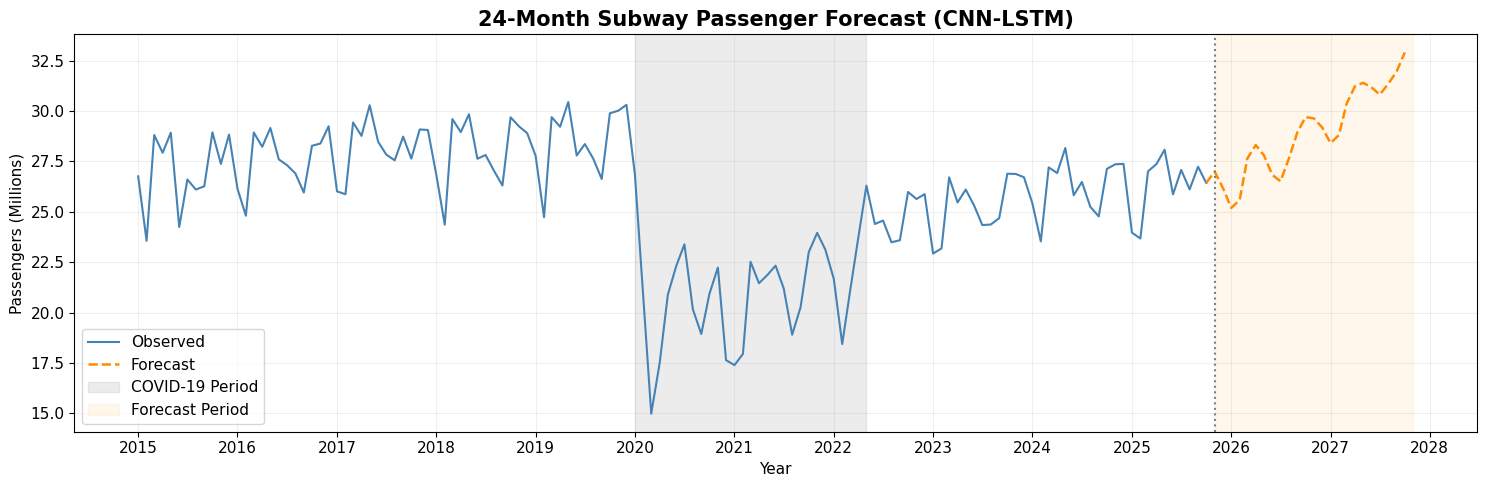

In [75]:
fig, ax = plt.subplots(figsize=(15, 5))

# 전체 실제 관측값
ax.plot(
    ts.index,
    ts / 1e6,
    color='steelblue',
    linewidth=1.5,
    label='Observed'
)

# 마지막 관측값과 미래 예측값 연결
forecast_line = pd.concat([
    ts.iloc[-1:],
    future_forecast
])

# 미래 예측값
ax.plot(
    forecast_line.index,
    forecast_line / 1e6,
    color='darkorange',
    linestyle='--',
    linewidth=1.8,
    label='Forecast'
)

# 코로나19 기간
ax.axvspan(
    covid_start,
    covid_end,
    color='gray',
    alpha=0.15,
    label='COVID-19 Period'
)

# 미래 예측 기간
ax.axvspan(
    future_forecast.index[0],
    future_forecast.index[-1] + pd.offsets.MonthBegin(1),
    color='orange',
    alpha=0.08,
    label='Forecast Period'
)

# 미래 예측 시작점
ax.axvline(
    future_forecast.index[0],
    color='gray',
    linestyle=':'
)

ax.set_title(
    f'24-Month Subway Passenger Forecast ({best_model_name})',
    fontsize=15,
    fontweight='bold'
)

ax.set_xlabel('Year')
ax.set_ylabel('Passengers (Millions)')

ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

#### 7.3.2 Detailed Forecast

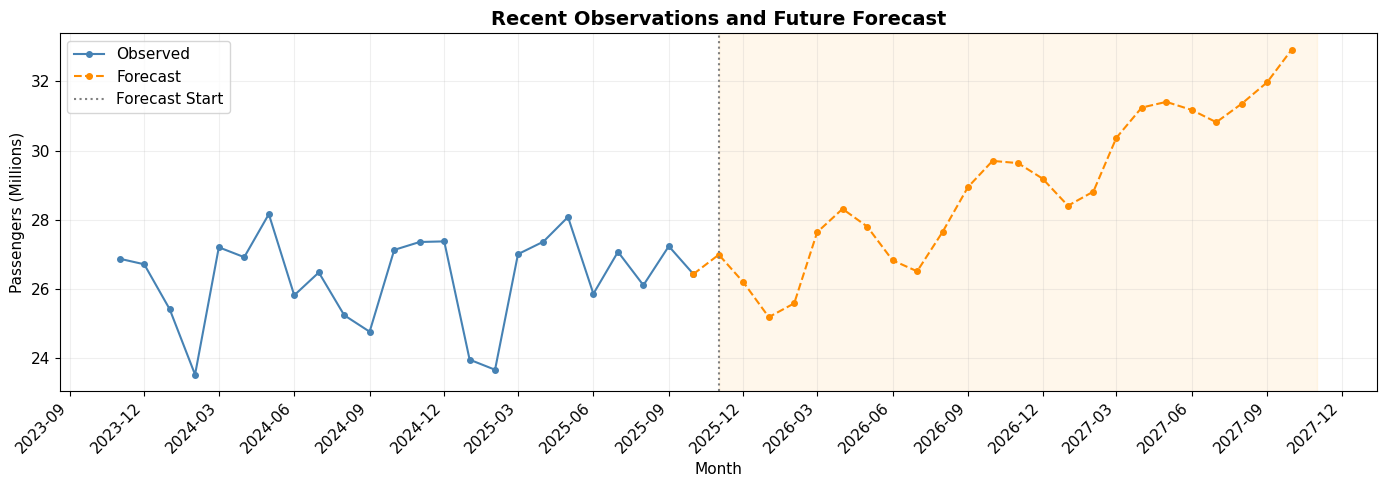

In [76]:
# 최근 24개월 실제 관측값
recent_actual = ts.iloc[-24:]

fig, ax = plt.subplots(figsize=(14, 5))

# 실제 관측값
ax.plot(
    recent_actual.index,
    recent_actual / 1e6,
    color='steelblue',
    marker='o',
    markersize=4,
    linewidth=1.5,
    label='Observed'
)

# 미래 예측값
ax.plot(
    forecast_line.index,
    forecast_line / 1e6,
    color='darkorange',
    marker='o',
    markersize=4,
    linestyle='--',
    linewidth=1.5,
    label='Forecast'
)

# 미래 예측 기간 표시
ax.axvspan(
    future_forecast.index[0],
    future_forecast.index[-1] + pd.offsets.MonthBegin(1),
    color='orange',
    alpha=0.08
)

ax.axvline(
    future_forecast.index[0],
    color='gray',
    linestyle=':',
    label='Forecast Start'
)

ax.set_title(
    'Recent Observations and Future Forecast',
    fontsize=14,
    fontweight='bold'
)

ax.set_xlabel('Month')
ax.set_ylabel('Passengers (Millions)')

ax.xaxis.set_major_locator(
    mdates.MonthLocator(interval=3)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter('%Y-%m')
)

plt.setp(
    ax.get_xticklabels(),
    rotation=45,
    ha='right'
)

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### 7.4 Forecast Summary

In [77]:
# 비교 기간 설정
forecast_periods = {
    'Last 12 Months (Observed)': ts.iloc[-12:],
    'First 12 Months (Forecast)': future_forecast.iloc[:12],
    'Next 12 Months (Forecast)': future_forecast.iloc[12:]
}

# 기간별 승객 수 요약
forecast_summary = pd.DataFrame([
    {
        'Period': period,
        'Start': values.index[0].strftime('%Y-%m'),
        'End': values.index[-1].strftime('%Y-%m'),
        'Mean': values.mean(),
        'Total': values.sum(),
        'Min': values.min(),
        'Max': values.max()
    }
    for period, values in forecast_periods.items()
])

display(
    forecast_summary.style
    .hide(axis='index')
    .format({
        'Mean': '{:,.0f}',
        'Total': '{:,.0f}',
        'Min': '{:,.0f}',
        'Max': '{:,.0f}'
    })
)

Period,Start,End,Mean,Total,Min,Max
Last 12 Months (Observed),2024-11,2025-10,"26,465,250","317,582,999","23,674,311","28,083,672"
First 12 Months (Forecast),2025-11,2026-10,"27,283,416","327,400,992","25,193,584","29,703,210"
Next 12 Months (Forecast),2026-11,2027-10,"30,609,072","367,308,861","28,409,262","32,916,082"


### 7.5 Forecast Diagnostics

#### 7.5.1 Difference Analysis

In [78]:
# 미래 예측 차분값의 표준화 역변환
future_diff = pd.Series(
    final_scaler.inverse_transform(
        future_scaled.reshape(-1, 1)
    ).flatten(),
    index=future_dates,
    name='Predicted Difference'
)

# 비교 구간 설정
difference_periods = {
    'Full Period (Observed)': final_diff,
    'Last 12 Months (Observed)': final_diff.iloc[-12:],
    'First 12 Months (Forecast)': future_diff.iloc[:12],
    'Next 12 Months (Forecast)': future_diff.iloc[12:]
}

# 차분값의 기초통계량 비교
difference_summary = pd.DataFrame([
    {
        'Period': period,
        'Mean': values.mean(),
        'Std': values.std(),
        'Min': values.min(),
        'Max': values.max(),
        'Sum': values.sum()
    }
    for period, values in difference_periods.items()
])

display(
    difference_summary.style
    .hide(axis='index')
    .format({
        column: '{:,.0f}'
        for column in difference_summary.columns
        if column != 'Period'
    })
)

Period,Mean,Std,Min,Max,Sum
Full Period (Observed),"-2,522","2,142,897","-6,150,400","5,252,760","-325,389"
Last 12 Months (Observed),"-58,157","1,725,668","-3,414,419","3,336,805","-697,884"
First 12 Months (Forecast),"272,276","988,410","-1,005,456","2,052,803","3,267,313"
Next 12 Months (Forecast),"267,739","678,268","-782,521","1,551,255","3,212,872"


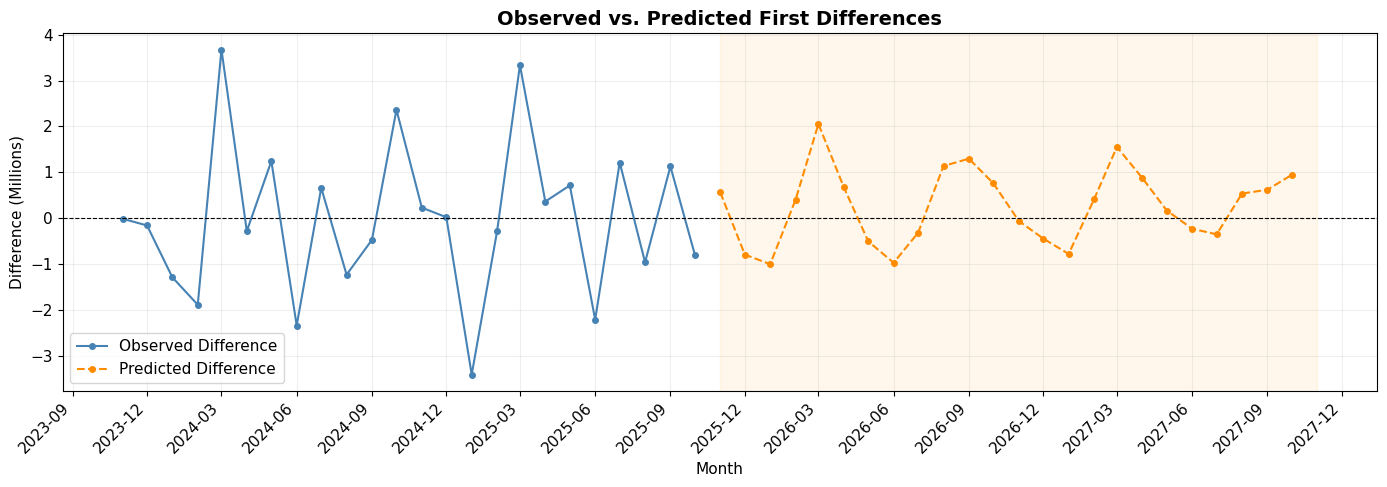

In [79]:
fig, ax = plt.subplots(figsize=(14, 5))

# 최근 24개월의 실제 차분값
recent_diff = final_diff.iloc[-24:]

ax.plot(
    recent_diff.index,
    recent_diff / 1e6,
    color='steelblue',
    marker='o',
    markersize=4,
    label='Observed Difference'
)

# 미래 예측 차분값
ax.plot(
    future_diff.index,
    future_diff / 1e6,
    color='darkorange',
    marker='o',
    markersize=4,
    linestyle='--',
    label='Predicted Difference'
)

# 0 기준선
ax.axhline(
    0,
    color='black',
    linestyle='--',
    linewidth=0.8
)

# 미래 예측 구간
ax.axvspan(
    future_dates[0],
    future_dates[-1] + pd.offsets.MonthBegin(1),
    color='orange',
    alpha=0.08
)

ax.set_title(
    'Observed vs. Predicted First Differences',
    fontsize=14,
    fontweight='bold'
)

ax.set_xlabel('Month')
ax.set_ylabel('Difference (Millions)')

ax.xaxis.set_major_locator(
    mdates.MonthLocator(interval=3)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter('%Y-%m')
)

plt.setp(ax.get_xticklabels(), rotation=45, ha='right')

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

#### 7.5.2 Cumulative Difference Analysis

In [80]:
# 예측 차분값의 누적합
cumulative_diff = future_diff.cumsum()

# 주요 시점의 누적 변화량
print(
    f'12-month cumulative change: '
    f'{cumulative_diff.iloc[11]:,.0f}'
)

print(
    f'24-month cumulative change: '
    f'{cumulative_diff.iloc[23]:,.0f}'
)

12-month cumulative change: 3,267,313
24-month cumulative change: 6,480,185


#### 7.5.3 Monthly Pattern Analysis

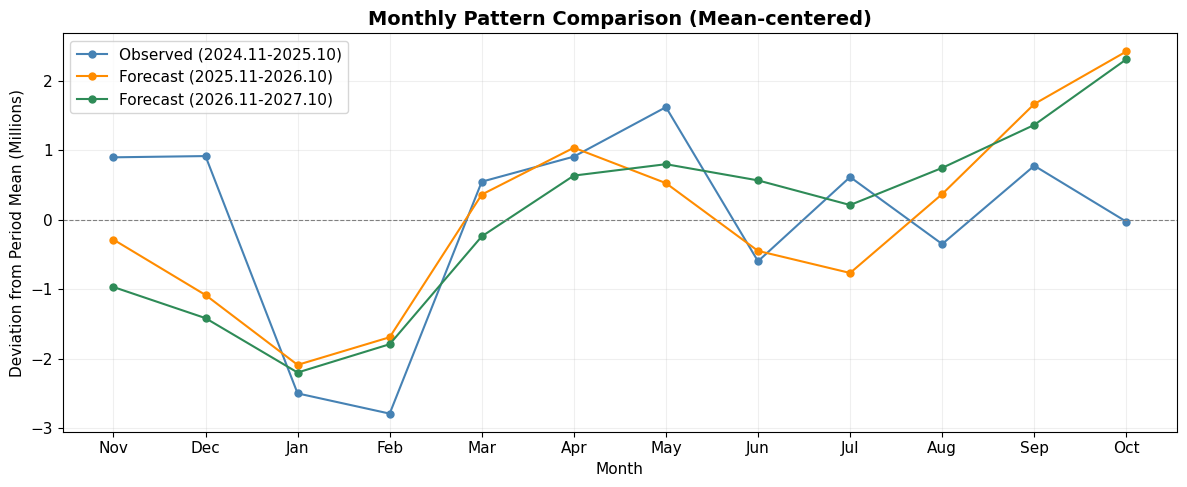

In [81]:
# 12개월 단위 비교 구간
seasonal_periods = {
    'Observed (2024.11-2025.10)': ts.iloc[-12:],
    'Forecast (2025.11-2026.10)': future_forecast.iloc[:12],
    'Forecast (2026.11-2027.10)': future_forecast.iloc[12:]
}

fig, ax = plt.subplots(figsize=(12, 5))

colors = [
    'steelblue',
    'darkorange',
    'seagreen'
]

for (period, values), color in zip(
    seasonal_periods.items(), colors
):

    # 기간별 평균 제거
    centered_values = values - values.mean()

    ax.plot(
        np.arange(1, 13),
        centered_values.to_numpy() / 1e6,
        marker='o',
        markersize=5,
        linewidth=1.5,
        color=color,
        label=period
    )

# 0 기준선
ax.axhline(
    0,
    color='gray',
    linestyle='--',
    linewidth=0.8
)

ax.set_xticks(range(1, 13))

ax.set_xticklabels([
    'Nov', 'Dec', 'Jan', 'Feb',
    'Mar', 'Apr', 'May', 'Jun',
    'Jul', 'Aug', 'Sep', 'Oct'
])

ax.set_title(
    'Monthly Pattern Comparison (Mean-centered)',
    fontsize=14,
    fontweight='bold'
)

ax.set_xlabel('Month')
ax.set_ylabel('Deviation from Period Mean (Millions)')

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

#### Interpretation

기간별 평균을 제거한 월별 변동 패턴을 비교하여
승객 수의 전반적인 수준 변화와 별개로 실제값과
예측값의 변동 형태를 살펴보았다.

미래 예측에서도 일부 반복적인 월별 변동이 나타났으나
실제 관측 구간의 세부적인 변동 형태와는 차이가 존재한다.

재귀적 예측 기간이 길어질수록 실제 관측값의 변동 패턴을
유지하는 데 한계가 있을 가능성을 고려할 수 있다.

다만 기간별 평균을 제거하더라도 구간 내부의 추세는
남아 있으므로 순수한 계절 성분의 비교로 해석하지 않는다.